# Function 1

<b> Description of the Sample Application:</b> Detect likely contamination sources in a two-dimensional area, such as a radiation field, where only proximity yields a non-zero reading. The system uses Bayesian optimisation to tune detection parameters and reliably identify both strong and weak sources.

## Change Log

| Date | Week | Changes Made |
|---|---|---|
| 22/07/2026 | Week 1 | 1. Initial Version with 10 Data Point |
| 06/08/2026 | Week 3 | 1. Consolidated Week 1 (UCB) and Week 2 (EI) logic into a single reusable bayesian_optimization_2d_step function.<br>2. Reduced exploration floor (xi_multiplier: 3.0 to 2.0, 80:20 to 70:30). |
| 13/08/2026 | Week 4 | 1. Input and output data points from Week 3 appended.<br>2. Reduced exploration floor (xi_multiplier: 2.0 to 1.5, 70:30 to 60:40). 
| 20/08/2026 | Week 5 | 1.  Input and output data points from Week 4 appended.<br>2. **Strategy change: switched from global to local (bounded) EI search**, restricted to a window around the current best point (0.731, 0.733), rather than continuing global exploration. <br>3. Reduced exploration floor further (xi_multiplier: 1.5 to 0.25, 60:40 to 20:80) to match the more decisive shift toward exploitation. | 02/02/2026 | Week 6 | 1. Appended Week 5's input and output data point.<br>2. Tested a narrower EI local search window (+/-0.05) for reference/diagnostic purposes.<br>3. Rather than submitting the EI-selected point, manually chose a proximity-stability test point 0.007 from the current best, much closer than EI's acquisition logic would ever select on its own, since EI avoids points immediately adjacent to existing samples (uncertainty there is already near-zero). Justified by having only 2 queries remaining after this week: resolving whether the current best is a genuine sharp peak or an isolated anomaly is higher information-value than another incremental refinement step. ||
| 09/02/2026 | Week 7 | 1. Appended Week 6's input and output data point. Output is positive, of the same order of magnitude as the current best, only 0.007 away. Confirms the proximity-stability hypothesis: this is a genuine.<br>2. Committed to **tight local refinement** (window +/-0.05 around current best, xi_multiplie r =0.05, 5:95 explore:exploit) now that the peak is confirmed real.
| 16/02/2026 | Week 8 | 1. Appended Week 7's input and output data point.<br>2. Only two points are positive (the original best and Week 6's point), both within 0.007 of each other. Every other point tested, even ones only 0.04-0.09 away, are negative. This confirms an extremely narrow peak, tighter than previously assumed.<br>3. Narrowed the local search window further (+/-0.05 to +/-0.005) and tested a direction not yet explored (increasing both x1 and x2 slightly, rather than x2 alone). | | 23/09/2026 | Week 9 | 1. Recorded Week 8's actual output: 1.1663787782344231e-17 -- positive (third positive point found), but does not beat the current best.<br>2. Appended Week 8's input and output data point..<br>3. Week 6 (x1 -0.005 from best) gave 5.61e-16; Week 8 (x1 +0.005 from best, same x2 shift) gave only 1.17e-17, marking a ~48x drop. The peak is steeper on the +x1 side than the -x1 side.<br>4. **Deliberate manual override again:** rather than following the GP's raw EI suggestion (which pointed toward a quadrant already tested negative in Week 3), manually extended the confirmed-productive -x1 direction further past Week 6's point. 
| 30/09/2026 | Week 10 | 1. Appended Week 9's output: 2.0339265002274336e-16, which is the fourth positive point found near the peak.<br>2. Appended Week 9's data point [0.721024, 0.743000].<br>3. **Peak bracketed, not just narrow:** the -x1/+x2 direction now shows a clean monotonic decay (Best > Week6 > Week9, all equally spaced), confirming the original best point is a genuine local maximum in that direction, not just 'somewhere on a slope'. The +x1/+x2 direction (Week 8) decays far more steeply, confirmed asymmetry, not noise.<br>4. EI's own suggestion at the tightest window now points to the one nearby quadrant never tested (x1 increasing, x2 decreasing), filling a genuine gap rather than repeating an already-negative direction. |
| 05/10/2026 | **Week 11** | 1. Appended Week 10's input/output: input `[0.736024, 0.728000]`, output `6.743943716784949e-16`.<br>2. **Strategy check performed, and strategy changed**: with Week 10's point, *all four* diagonal neighbours of the current best (within a 0.014 radius) are now positive. A single best point could be an isolated spike; four consistently positive neighbours look like a genuine basin/cluster instead. <br>3. **New strategy: cluster-informed local search**: introduced a lightweight 2-cluster split (KMeans on sign(y) and log10&#124;y&#124;) to separate the "promising" near-best points from the "background" cluster, then anchored this week's EI search on the **output-weighted centroid of the promising cluster** rather than on the single argmax(Y) point, and tightened the window further (+/-0.004, xi_multiplier = 0.01) given the 20-point evidence base.<br>5. **Visualisation updated**: added a cluster-scatter diagnostic plot and an EI-heatmap around the new centroid-anchored window, and refreshed the weekly dashboard/convergence plot with Week 10's real outcome
| 14/10/2026 | **Week 12** | 1. Appended Week 11's input/output: input `[0.730901, 0.737686]`, output `1.0873078549064772e-16`.<br>2. **Strategy check- diagnosis corrected:** Week 11's point was the closest query yet to the best (0.0047 away) but only the second-lowest basin output, and the GP had predicted 4.108e-06 (a 3.8e10x overshoot). Earlier notes claimed it to be a noise / a rugged surface; that was **wrong**. Root cause: the GP is fitted on raw y, whose spread (~8e-4, set by one -3.6e-3 reading) is ~12 orders of magnitude larger than the basin's own spread (3e-16), so the basin is invisible to it.<br>3. **New model**: fitted an isotropic Gaussian in **log-space** to the 6 basin points. It reproduces all six outputs to 2% (rms ln-residual 0.023) and ranks them *exactly* by distance to the fitted centre (0.6972, 0.6973), which resolves the "closer to best is not higher" anomaly (the basin is a **flank**, not a peak: the best point is 0.049 / 5.2 sigma from the implied centre). Leave-one-out predictions land within 0.87-1.28x of actual.<br>4. PCA analysis (global + local) added: local PC2 (13.6% of spatial variance, r = -0.857 with output) points along the same direction as best-to-centre (|cos| = 0.998).<br>5. **Strategy change**: abandoned local EI refinement around the best point (and the earlier plan to repeat it - a repeat gives no new information if the function is deterministic). Week 12 queries the fitted centre instead
| 21/10/2026 | **Week 13 (Final Query)** | 1. Appended Week 12's input/output: input `[0.697190, 0.697252]`, output `4.7435597197972983e-07` - a **new best**, ~6e8x the old best (7.71e-16).<br>2. **Strategy check performed, and strategy changed**: the Week 12 local log-Gaussian model predicted ~7e-10 (under-predicting by ~650x) while the *global two-source log-magnitude model* (fitted to all points) was within ~6x. It places a much stronger source near (0.628, 0.629); the basin was a flank of it.<br>3. **New acquisition rule for the final query**: expected improvement computed from the two-source model with the **sign uncertainty modelled explicitly** (an unknown sign-flip radius between the negative -3.6e-3 reading and the positive Week 12 point). Chosen rule: largest EI subject to P(beat best) >= 50%, along the ray from the Week 12 point toward the strong source.<br>4. Historical Week 1-12 modelling cells now run on a **21-point snapshot** (so `argmax(Y)` anchors keep their original meaning); the Week 13 section uses all 22 points.<br>5. **Visualisation**: new two-source map, risk/reward-versus-radius chart, refreshed convergence plot and 4-panel dashboard. |||


# Weekly Progress Log

| Week | Method | Exploration:Exploitation | Query (x1, x2) | Output (y) | Best-so-far |
|---|---|---|---|---|---|
| Initial | Provided data (10 points) | - | - | - | 7.710875e-16 |
| 1 | GP-UCB (β=2.5), space-filling exploration | 90:10 | (0.617450, 0.872483) | -4.579196e-42 | 7.710875e-16 |
| 2 | GP-Expected Improvement (EI), exploration floor via scaled xi (xi_multiplier=3.0) | 80:20 | (0.785234, 0.798657) | 1.170424e-37 | 7.710875e-16 |
| 3 | GP-Expected Improvement (EI), reduced exploration floor (xi_multiplier=2.0) | 70:30 | (0.818791, 0.711409) | -5.679812e-31 | 7.710875e-16 |
| 4 | GP-Expected Improvement (EI), further reduced exploration floor (xi_multiplier=1.5) | 60:40 | (0.409396, 0.040268) | -6.737500e-102 | 7.710875e-16 |
| 5 | GP-Expected Improvement (EI), local search bounded to +/-0.15 around the current best (xi_multiplier=0.25) | 20:80 | (0.770285, 0.746087) | -4.703971e-26 | 7.710875e-16 |
| 6 | Deliberate proximity-stability test (manual override) | 0:100 | (0.726024, 0.738000) | 5.606704e-16 | 7.710875e-16 |
| 7 | GP-Expected Improvement (EI), tight local refinement (window +/-0.05, xi_multiplier = 0.05) | 5:95 | (0.732030, 0.783000) | -1.028481e-24 | 7.710875e-16 |
| 8 | GP-Expected Improvement (EI), extremely narrow local refinement (window +/-0.005, xi_multiplier = 0.02) | 2:98 | (0.736024, 0.738000) | 1.166379e-17 | 7.710875e-16 |
| 9 | Manual override: extending the confirmed-productive -x1,+x2 direction past Week 6 | 0:100 | (0.721024, 0.743000) | 2.033927e-16 | 7.710875e-16 |
| 10 | GP-Expected Improvement (EI), extremely narrow window (+/-0.005) targeting the last untested (+x1,-x2) quadrant | 2:98 | (0.736024, 0.728000) | **6.743944e-16** | 7.710875e-16 |
| 11 | GP-Expected Improvement (EI), cluster-informed local search, anchored on the output-weighted centroid of the "promising cluster" (window +/-0.004, xi_multiplier=0.01) | ~1:99 | (0.730901, 0.737686) | 1.087308e-16 | 7.710875e-16 |
| 12 | **Log-space Gaussian model** fitted to the 6 basin points (leave-one-out validated); query placed at the fitted source centre, ~0.05 away from the best point | ~20:80 | (0.697190, 0.697252) | **4.743560e-07** (new best, ~6e8x the old best) | **4.743560e-07** |
| 13 (Final) | **Two-source log-magnitude model** refit on all 22 points; EI with sign-uncertainty along the ray toward the strong source, rule: max EI s.t. P(beat best) >= 50% | ~0:100 | - | - | - |

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel, Matern
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.stats import norm
from plotting_utils import plot_2d_bo_state, plot_convergence
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA                  
from sklearn.preprocessing import StandardScaler  
from scipy.optimize import least_squares

# Load and Analyse the Data

In [12]:
# File Names
input_file  = "initial_inputs.npy"
output_file = "initial_outputs.npy"

# Load the Files
X              = np.load(input_file)
Y              = np.load(output_file)

In [14]:
# New data from Week 1 submission
X_w1_new_point = np.array([0.644295, 0.872483]      , dtype=np.float64)    # from input.txt
Y_w1_new_point = np.array([-4.57919574117409e-42]   , dtype=np.float64)    # from output.txt

# New data from Week 2 submission
X_w2_new_point = np.array([0.785234, 0.798657]      , dtype=np.float64)    # from input.txt
Y_w2_new_point = np.array([1.1704238583798859e-37]  , dtype=np.float64)   # from output.txt

# New data from Week 3 submission
X_w3_new_point = np.array([0.818791, 0.711409]      , dtype=np.float64)   # from input.txt
Y_w3_new_point = np.array([-5.679811964041589e-31]  , dtype=np.float64)   # from output.txt

# New data from Week 4 submission
X_w4_new_point = np.array([0.409396, 0.040268]      , dtype=np.float64)   # from input.txt
Y_w4_new_point = np.array([-6.7375004083242144e-102], dtype=np.float64)   # from output.txt

# New data from Week 5 submission
X_w5_new_point = np.array([0.770285, 0.746087]      , dtype=np.float64)   # from input.txt
Y_w5_new_point = np.array([-4.7039714109697477e-26] , dtype=np.float64)   # from output.txt

# New data from Week 6 submission
X_w6_new_point = np.array([0.726024, 0.738000]      , dtype=np.float64)   # from input.txt
Y_w6_new_point = np.array([5.606704199651088e-16]   , dtype=np.float64)   # from output.txt

# New data from Week 7 submission
X_w7_new_point = np.array([0.73203, 0.783]          , dtype=np.float64)  # from input.txt
Y_w7_new_point = np.array([-1.0284805649443051e-24] , dtype=np.float64)  # from output.txt

# New data from Week 8 submission
X_w8_new_point = np.array([0.736024, 0.738000]      , dtype=np.float64)   # from input.txt
Y_w8_new_point = np.array([1.1663787782344231e-17]  , dtype=np.float64)   # from output.txt

# New data from Week 9 submission
X_w9_new_point = np.array([0.721024, 0.743000]      , dtype=np.float64)   # from input.txt
Y_w9_new_point = np.array([2.0339265002274336e-16]  , dtype=np.float64)   # from output.txt

# New data from Week 10 submission
X_w10_new_point = np.array([0.736024, 0.728000]      , dtype=np.float64)   # from input.txt
Y_w10_new_point = np.array([6.743943716784949e-16]   , dtype=np.float64)   # from output.txt

# New data from Week 11 submission
X_w11_new_point = np.array([0.730901, 0.737686]      , dtype=np.float64)   # from input.txt
Y_w11_new_point = np.array([1.0873078549064772e-16]  , dtype=np.float64)   # from output.txt

# New data from Week 12 submission
X_w12_new_point = np.array([0.69719, 0.697252]       , dtype=np.float64)   # from input.txt
Y_w12_new_point = np.array([4.7435597197972983e-07]  , dtype=np.float64)   # from output.txt

In [16]:
# Append the new data points
X_updated      = np.vstack((X, X_w1_new_point
                             , X_w2_new_point
                             , X_w3_new_point
                             , X_w4_new_point
                             , X_w5_new_point
                             , X_w6_new_point
                             , X_w7_new_point
                             , X_w8_new_point
                             , X_w9_new_point
                             , X_w10_new_point
                             , X_w11_new_point
                             , X_w12_new_point
                           ))
Y_updated      = np.append(Y, [Y_w1_new_point
                            , Y_w2_new_point
                            , Y_w3_new_point
                            , Y_w4_new_point
                            , Y_w5_new_point
                            , Y_w6_new_point
                            , Y_w7_new_point
                            , Y_w8_new_point
                            , Y_w9_new_point
                            , Y_w10_new_point
                            , Y_w11_new_point
                            , Y_w12_new_point
                              ])


In [18]:
print(X_updated)
print(Y_updated)

# Save the updated arrays
#np.save(r"initial_inputs.npy", X_updated)
#np.save(r"initial_outputs.npy", Y_updated)

[[0.31940389 0.76295937]
 [0.57432921 0.8798981 ]
 [0.73102363 0.73299988]
 [0.84035342 0.26473161]
 [0.65011406 0.68152635]
 [0.41043714 0.1475543 ]
 [0.31269116 0.07872278]
 [0.68341817 0.86105746]
 [0.08250725 0.40348751]
 [0.88388983 0.58225397]
 [0.644295   0.872483  ]
 [0.785234   0.798657  ]
 [0.818791   0.711409  ]
 [0.409396   0.040268  ]
 [0.770285   0.746087  ]
 [0.726024   0.738     ]
 [0.73203    0.783     ]
 [0.736024   0.738     ]
 [0.721024   0.743     ]
 [0.736024   0.728     ]
 [0.730901   0.737686  ]
 [0.69719    0.697252  ]]
[ 1.32267704e-079  1.03307824e-046  7.71087511e-016  3.34177101e-124
 -3.60606264e-003 -2.15924904e-054 -2.08909327e-091  2.53500115e-040
  3.60677119e-081  6.22985647e-048 -4.57919574e-042  1.17042386e-037
 -5.67981196e-031 -6.73750041e-102 -4.70397141e-026  5.60670420e-016
 -1.02848056e-024  1.16637878e-017  2.03392650e-016  6.74394372e-016
  1.08730785e-016  4.74355972e-007]


In [20]:
# Assign X = X_updated and Y = Y_updated
X          = X_updated
Y          = Y_updated

# Analyse the Input Data
print("Input  Shape:", X.shape)
print("Inputs:\n", X)
print()

# Analyse the Output Data
print("Output Shape:", Y.shape)
print("Outputs:\n", Y)
print()
print("Minimum and Maximum Values of Output:\n")
print("Min:", Y.min(), " Max:", Y.max())
print("Best point:", X[np.argmax(Y)], "-> Output =", Y.max())
print()

# Converting the Input and Output into a DataFram
df           = pd.DataFrame(X, columns = [f'Input_{i+1}' for i in range(X.shape[1])])
df['Output'] = Y
print("Data Frame:\n", df)

Input  Shape: (22, 2)
Inputs:
 [[0.31940389 0.76295937]
 [0.57432921 0.8798981 ]
 [0.73102363 0.73299988]
 [0.84035342 0.26473161]
 [0.65011406 0.68152635]
 [0.41043714 0.1475543 ]
 [0.31269116 0.07872278]
 [0.68341817 0.86105746]
 [0.08250725 0.40348751]
 [0.88388983 0.58225397]
 [0.644295   0.872483  ]
 [0.785234   0.798657  ]
 [0.818791   0.711409  ]
 [0.409396   0.040268  ]
 [0.770285   0.746087  ]
 [0.726024   0.738     ]
 [0.73203    0.783     ]
 [0.736024   0.738     ]
 [0.721024   0.743     ]
 [0.736024   0.728     ]
 [0.730901   0.737686  ]
 [0.69719    0.697252  ]]

Output Shape: (22,)
Outputs:
 [ 1.32267704e-079  1.03307824e-046  7.71087511e-016  3.34177101e-124
 -3.60606264e-003 -2.15924904e-054 -2.08909327e-091  2.53500115e-040
  3.60677119e-081  6.22985647e-048 -4.57919574e-042  1.17042386e-037
 -5.67981196e-031 -6.73750041e-102 -4.70397141e-026  5.60670420e-016
 -1.02848056e-024  1.16637878e-017  2.03392650e-016  6.74394372e-016
  1.08730785e-016  4.74355972e-007]

Minim

# Data Exploration

In [23]:
# Basic Staistics
print("Display Basic Statistics for the Dataset\n",df.describe())

Display Basic Statistics for the Dataset
          Input_1    Input_2        Output
count  22.000000  22.000000  2.200000e+01
mean    0.636154   0.624047 -1.638904e-04
std     0.202712   0.259122  7.688200e-04
min     0.082507   0.040268 -3.606063e-03
25%     0.591821   0.607072 -1.619437e-54
50%     0.723524   0.735343  3.114928e-48
75%     0.736024   0.758741  8.446404e-17
max     0.883890   0.879898  4.743560e-07


In [25]:
# Check for Missing Values in the Data Set
print("Missing Values in the Dataset\n",df.isnull().sum())

Missing Values in the Dataset
 Input_1    0
Input_2    0
Output     0
dtype: int64


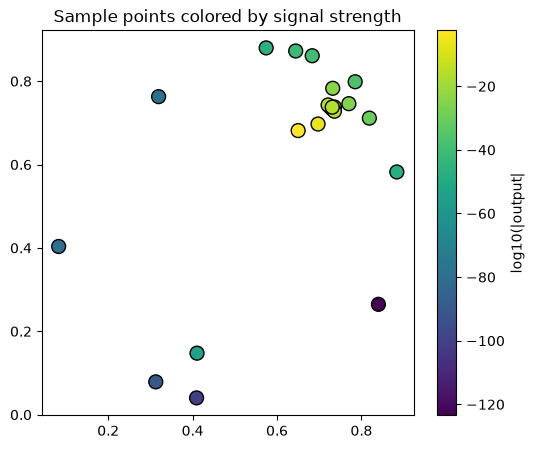

In [27]:
# Scatter Plot
magnitude = np.log10(np.abs(Y) + 1e-300)
fig, ax   = plt.subplots(figsize = (6,5))
sc        = ax.scatter(X[:,0], X[:,1], c = magnitude, cmap = 'viridis', s = 100, edgecolor = 'black')
plt.colorbar(sc, label = 'log10(|output|')
ax.set_title('Sample points colored by signal strength')
plt.show()

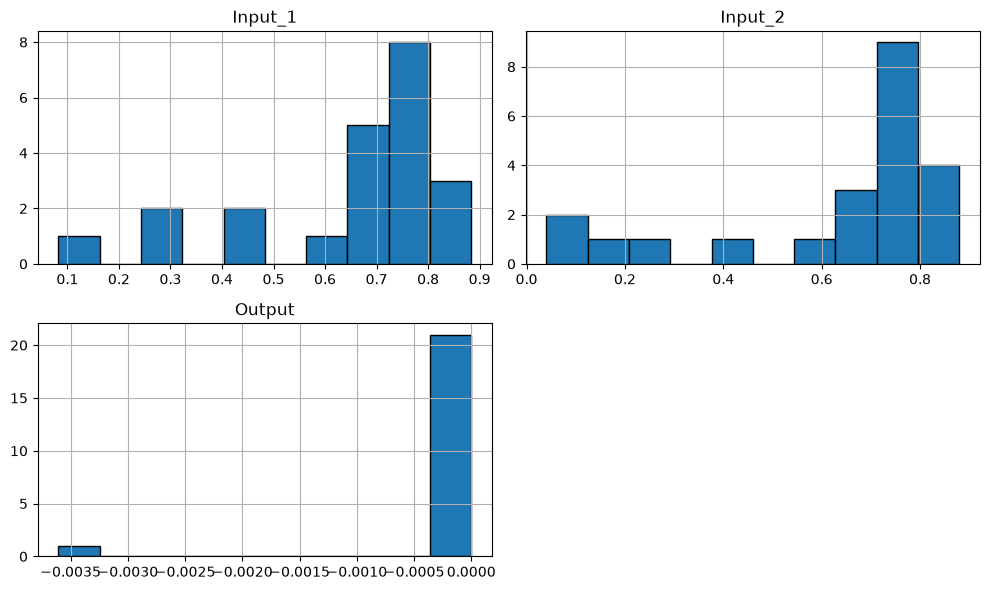

In [29]:
# Plot Histogram Visualisation for the columns of the DataFrame
df.hist(figsize = (10, 6), bins = 10, edgecolor = 'black' )
plt.tight_layout()
plt.show()

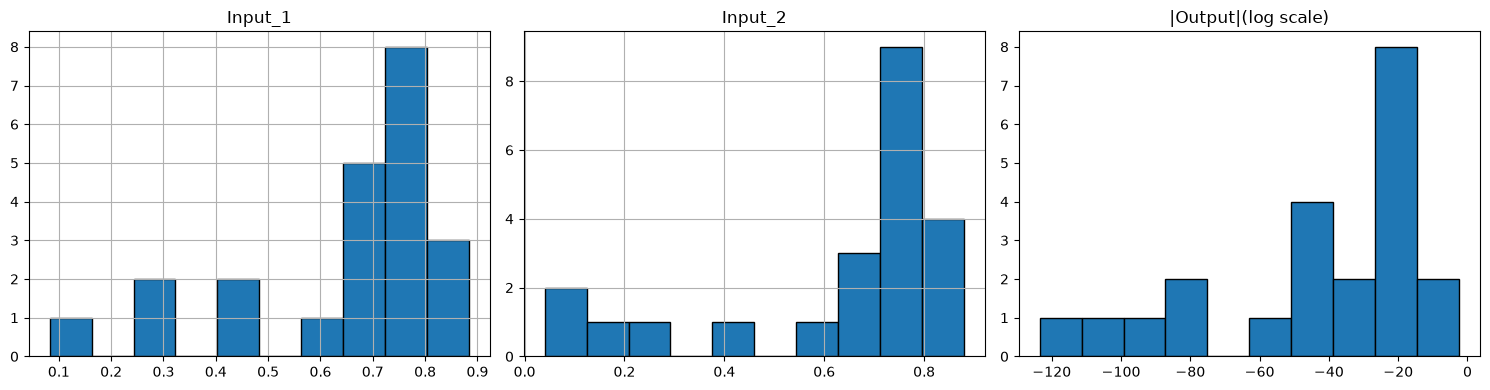

In [31]:
# In the above histogram for the output column, almost every bar seems to be crammed into a single bin near zero, which is not very informative.
# Plotting the column histograms using log scale for Output column
fig, axes = plt.subplots(1,3, figsize = (15,4))

df['Input_1'].hist(ax = axes[0], bins = 10, edgecolor = 'black')
axes[0].set_title('Input_1')

df['Input_2'].hist(ax = axes[1], bins = 10, edgecolor = 'black')
axes[1].set_title('Input_2')

magnitude = np.where(Y != 0, np.log10(np.abs(Y) + 1e-300), np.nan)
axes[2].hist(magnitude, bins = 10, edgecolor = 'black')
axes[2].set_title('|Output|(log scale)')


plt.tight_layout()
plt.show()

# Nearest-Pair Check

In [34]:
D      = squareform(pdist(X))
i, j   = np.unravel_index(np.argmin(D + np.eye(len(X))*99), D.shape)
print(f"Closest pair: idx {i} & {j}, distance={D[i,j]:.4f}, y_i={Y[i]:.3e}, y_j={Y[j]:.3e}")

Closest pair: idx 2 & 20, distance=0.0047, y_i=7.711e-16, y_j=1.087e-16


## Week 13 note: historical snapshot used for the Weeks 1-12 modelling cells

**Week 13 Change:** The full 22-point dataset (including Week 12's 4.74e-7 reading) is loaded above and used for the data exploration. The Week 1-12 modelling cells below, however, are *historical records of what was run and submitted in each week*. Several of them anchor on `argmax(Y)`, which would silently move to the Week 12 point and change what those weeks' analyses mean. They therefore run on the **21-point snapshot** (Weeks 1-11 data) that existed when they were originally executed. The Week 13 section (after the Week 12 section) switches back to all 22 points.

In [37]:
# Keeping the full dataset, and running the historical Week 1-12 cells on the 21-point snapshot
X_full, Y_full = X.copy(), Y.copy()           # all 22 points (Initial 10 + Weeks 1-12)
X, Y           = X_full[:-1].copy(), Y_full[:-1].copy()   # snapshot as it stood before Week 12's result
print(f"Full dataset: {len(Y_full)} points | historical snapshot: {len(Y)} points (best = {Y.max():.6e})")

Full dataset: 22 points | historical snapshot: 21 points (best = 7.710875e-16)


# Initialize Gaussian Process

In [40]:
#Define the kernel and initialise the GP model

# Week 1 ( Using RBF GP Surrogate )
kernel_rbf   = ConstantKernel(1.0) * RBF(length_scale = 0.2, length_scale_bounds = (0.02, 1.0)) \
                + WhiteKernel(noise_level = 1e-6, noise_level_bounds = (1e-10, 1e-2))
gpr          = GaussianProcessRegressor(kernel = kernel_rbf, normalize_y = True, n_restarts_optimizer = 10, random_state = 0 )

# Fit the Gaussian Processes to existing data

In [43]:
# Train the model

# Week 1 fit to RBF GP Surrugate
gpr.fit(X, Y)
print("Learned kernel (Week 1): ", gpr.kernel_)

Learned kernel (Week 1):  1.18**2 * RBF(length_scale=0.0519) + WhiteKernel(noise_level=1.99e-06)


# Week 1: Compute the UCB acquisition function

- UCB(x)=μ(x)+β⋅σ(x)
- A high beta favors exploration (uncertainty) over exploitation (predicted mean).
- Week 1 uses beta = 2.5, reflecting the 90:10 exploration-heavy strategy.

In [47]:
grid_res   = 150
xs         = np.linspace(0, 1, grid_res)
ys         = np.linspace(0, 1, grid_res)
gx, gy     = np.meshgrid(xs, ys)
candidates = np.column_stack([gx.ravel(), gy.ravel()])

mu, std    = gpr.predict(candidates, return_std = True)

# Setting a higher beta(= 2.5) for Week -1
beta       = 2.5
ucb        = mu + beta * std

best_ucb_idx = np.argmax(ucb)
next_point   = candidates[best_ucb_idx]

print(f"Suggested next Query Point: {next_point}")
print(f"Predicted Mean(μ): {mu[best_ucb_idx]:.6e}")
print(f"Predicted Std (σ): {std[best_ucb_idx]:.6e}")
print(f"UCB Score: {ucb[best_ucb_idx]:.6e}")

Suggested next Query Point: [0.30201342 0.20134228]
Predicted Mean(μ): -1.534330e-04
Predicted Std (σ): 9.045371e-04
UCB Score: 2.107910e-03


# Perform Visualisation ( Week 1 )

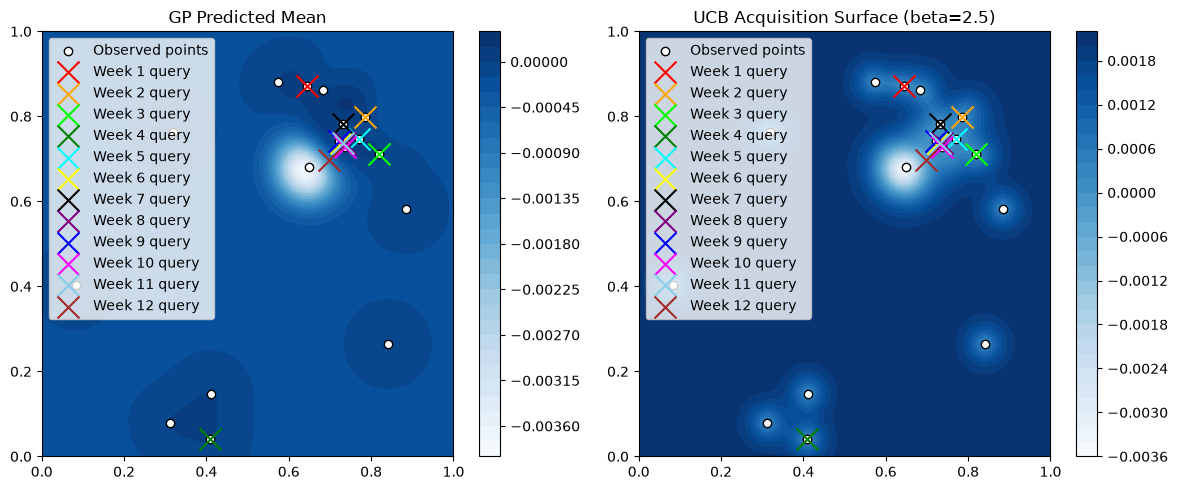

In [52]:
fig, axes  = plt.subplots(1,2, figsize = (12, 5))

# Predicted mean surface
c0 = axes[0].contourf(gx, gy, mu.reshape(gx.shape), levels=30, cmap="Blues")
axes[0].scatter(X[:, 0], X[:, 1] , c = "white" , edgecolor = "black", label = "Observed points")
axes[0].scatter(*X_w1_new_point  , c = "red"   , marker    = "x"    , s=250, label = "Week 1 query")
axes[0].scatter(*X_w2_new_point  , c = "orange", marker    = "x"    , s=250, label = "Week 2 query")
axes[0].scatter(*X_w3_new_point  , c = "lime"  , marker    = "x"    , s=250, label = "Week 3 query")
axes[0].scatter(*X_w4_new_point  , c = "green" , marker    = "x"    , s=250, label = "Week 4 query")
axes[0].scatter(*X_w5_new_point  , c = "cyan"  , marker    = "x"    , s=250, label = "Week 5 query")
axes[0].scatter(*X_w6_new_point  , c = "yellow", marker    = "x"    , s=250, label = "Week 6 query")
axes[0].scatter(*X_w7_new_point  , c = "black" , marker    = "x"    , s=250, label = "Week 7 query")
axes[0].scatter(*X_w8_new_point  , c = "purple", marker    = "x"    , s=250, label = "Week 8 query")
axes[0].scatter(*X_w9_new_point  , c = "blue"  , marker    = "x"    , s=250, label = "Week 9 query")
axes[0].scatter(*X_w10_new_point , c = "magenta",marker    = "x"    , s=250, label = "Week 10 query")
axes[0].scatter(*X_w11_new_point , c = "skyblue",marker    = "x"    , s=250, label = "Week 11 query")
axes[0].scatter(*X_w12_new_point , c = "brown"  ,marker    = "x"    , s=250, label = "Week 12 query")

axes[0].set_title("GP Predicted Mean")
axes[0].legend(loc='upper left')
fig.colorbar(c0, ax=axes[0])

# UCB acquisition surface
c1 = axes[1].contourf(gx, gy, ucb.reshape(gx.shape), levels=30, cmap="Blues")
axes[1].scatter(X[:, 0], X[:, 1] , c = "white" , edgecolor = "black", label = "Observed points")
axes[1].scatter(*X_w1_new_point  , c = "red"   , marker    = "x"    , s     = 250, label = "Week 1 query")
axes[1].scatter(*X_w2_new_point  , c = "orange", marker    = "x"    , s     = 250, label = "Week 2 query")
axes[1].scatter(*X_w3_new_point  , c = "lime"  , marker    = "x"    , s     = 250, label = "Week 3 query")
axes[1].scatter(*X_w4_new_point  , c = "green" , marker    = "x"    , s     = 250, label = "Week 4 query")
axes[1].scatter(*X_w5_new_point  , c = "cyan"  , marker    = "x"    , s     = 250, label = "Week 5 query")
axes[1].scatter(*X_w6_new_point  , c = "yellow", marker    = "x"    , s     = 250, label = "Week 6 query")
axes[1].scatter(*X_w7_new_point  , c = "black" , marker    = "x"    , s     = 250, label = "Week 7 query")
axes[1].scatter(*X_w8_new_point  , c = "purple", marker    = "x"    , s     = 250, label = "Week 8 query")
axes[1].scatter(*X_w9_new_point  , c = "blue"  , marker    = "x"    , s     = 250, label = "Week 9 query")
axes[1].scatter(*X_w10_new_point , c = "magenta",marker    = "x"    , s     = 250, label = "Week 10 query")
axes[1].scatter(*X_w11_new_point , c = "skyblue",marker    = "x"    , s     = 250, label = "Week 11 query")
axes[1].scatter(*X_w12_new_point , c = "brown"  ,marker    = "x"    , s     = 250, label = "Week 12 query")

axes[1].set_title("UCB Acquisition Surface (beta=2.5)")
axes[1].legend(loc='upper left')
fig.colorbar(c1, ax=axes[1])

plt.tight_layout()
plt.show()

# Week 2: Compute the EI acquisition Function

In [55]:
grid_res = 150

# Define Expected Improvement Acquisition Function
def expected_improvement(mu, sigma, y_best, xi):
    """EI = E[max(f(x) - f(x_best), 0)]"""
    sigma   = np.maximum(sigma, 1e-9)
    z       = (mu - y_best - xi) / sigma
    ei      = (mu - y_best - xi) * norm.cdf(z) + sigma * norm.pdf(z)
    ei[sigma < 1e-9] = 0.0
    return ei

# Define Bayesian Optimisation Function for Week2
def bayesian_optimization_2d_step(X_samples, y_samples, bounds, xi_multiplier = 3.0, grid_res = grid_res, nu = 2.5):
    """
    Single-step 2D Bayesian Optimization, fit a Matern GP, evaluate EI over a dense candidate grid, and return the next query point.
    """

    # Using Matern GP Surrogate
    kernel_matern = ConstantKernel(1.0) * Matern(length_scale = 0.2, length_scale_bounds = (0.02, 1.0), nu = nu) \
                        + WhiteKernel(noise_level = 1e-6, noise_level_bounds = (1e-10, 1e-2))
    
    grp_matern    = GaussianProcessRegressor(kernel = kernel_matern, normalize_y = True, n_restarts_optimizer = 10, random_state = 0 )

    grp_matern.fit(X_samples, y_samples)
    
    #print("Learned kernel (Week 2): ", grp_matern.kernel_)
    
    # Grid sampling: build a candidate grid over the bounds
    axes         = [np.linspace(b[0], b[1], grid_res) for b in bounds]
    mesh         = np.meshgrid(*axes)
    candidates   = np.column_stack([m.ravel() for m in mesh])

    mu, sigma    = grp_matern.predict(candidates, return_std = True)
    
    xi           = xi_multiplier * y_samples.std()
    ei           = expected_improvement(mu, sigma, y_samples.max(), xi=xi)

    best_idx     = np.argmax(ei)
    X_next       = candidates[best_idx]

    return {
        'gp': grp_matern, 'mesh': mesh, 'candidates': candidates,
        'mu': mu, 'sigma': sigma, 'ei': ei, 'xi': xi,
        'X_next': X_next, 'ei_at_next': ei[best_idx],
        'mu_at_next': mu[best_idx], 'sigma_at_next': sigma[best_idx],
    }
    

result           = bayesian_optimization_2d_step(X, Y, bounds = [(0, 0.999999), (0, 0.999999)], xi_multiplier = 3.0 )

next_point       = result['X_next']

print("Learned kernel          :", result['gp'].kernel_)
print(f"Exploration floor (xi) : {result['xi']:.6e}")
print(f"\nNext query point (EI): {next_point}")
print(f"EI value at next point : {result['ei_at_next']:.6e}")
print(f"Predicted mean (mu)    : {result['mu_at_next']:.6e}")
print(f"Predicted std (sigma)  : {result['sigma_at_next']:.6e}")

Learned kernel          : 1.41**2 * Matern(length_scale=0.0932, nu=2.5) + WhiteKernel(noise_level=1e-10)
Exploration floor (xi) : 2.303829e-03

Next query point (EI): [0.37583855 0.999999  ]
EI value at next point : 4.217279e-06
Predicted mean (mu)    : -1.465604e-04
Predicted std (sigma)  : 1.076256e-03


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


# Week 2 Visualisation

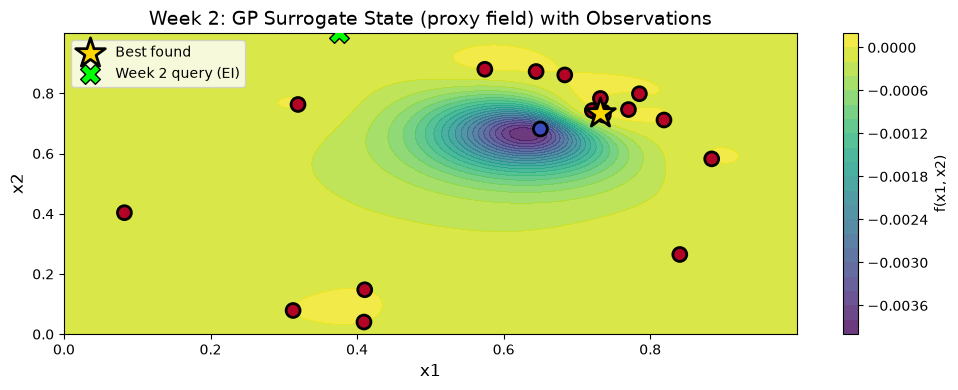

In [58]:
gx, gy   = result['mesh']
Z        = result['mu'].reshape(gx.shape)

fig, ax  = plot_2d_bo_state( gx, gy, Z, X, Y, title = "Week 2: GP Surrogate State (proxy field) with Observations")
ax.scatter(*next_point, marker = 'X', s = 200, c = 'lime', edgecolor = 'black', label = 'Week 2 query (EI)', zorder = 12)
ax.legend(loc = 'upper left')
plt.show()

# Week 3: Consolidated Bayesian Optimization Function

In [61]:
# Define UCB Acquisition Function
def upper_confidence_bound(mu, sigma, beta=2.0):
    """UCB = mean + beta * std"""
    return mu + beta * sigma

# Define Expected Improvement Acquisition Function
def expected_improvement(mu, sigma, y_best, xi):
    """EI = E[max(f(x) - f(x_best), 0)]"""
    sigma   = np.maximum(sigma, 1e-9)
    z       = (mu - y_best - xi) / sigma
    ei      = (mu - y_best - xi) * norm.cdf(z) + sigma * norm.pdf(z)
    ei[sigma < 1e-9] = 0.0
    return ei

# Week 3: Consolidated Bayesian Optimization Function
def bayesian_optimization_2d_step(X_samples, y_samples, bounds, acquisition = 'ei',
                                   xi_multiplier = 2.0, beta = 2.0, grid_res = 150, nu = 2.5,
                                   plot = True, week_label = 'Week'):

    kernel_matern = ConstantKernel(1.0) * Matern(length_scale = 0.2, length_scale_bounds =( 0.02, 1.0), nu = nu) \
                        + WhiteKernel(noise_level = 1e-6, noise_level_bounds = (1e-10, 1e-2))

    grp_matern   = GaussianProcessRegressor(kernel = kernel_matern, normalize_y = True,
                                            n_restarts_optimizer = 10, random_state = 0)
    grp_matern.fit(X_samples, y_samples)

    # Grid sampling: build a candidate grid over the bounds
    axes         = [np.linspace(b[0], b[1], grid_res) for b in bounds]
    mesh         = np.meshgrid(*axes)
    candidates   = np.column_stack([m.ravel() for m in mesh])

    mu, sigma    = grp_matern.predict(candidates, return_std = True)

    if acquisition == 'ei':
        xi       = xi_multiplier * y_samples.std()
        acq_vals = expected_improvement(mu, sigma, y_samples.max(), xi=xi)
    else:
        xi       = None
        acq_vals = upper_confidence_bound(mu, sigma, beta = beta)

    best_idx     = np.argmax(acq_vals)
    X_next       = candidates[best_idx]

    print(f"--- {week_label}: Bayesian Optimization ---")
    print(f"Learned kernel        : {grp_matern.kernel_}")
    if xi is not None:
        print(f"Acquisition           : EI (xi = {xi:.6e})")
    else:
        print(f"Acquisition           : UCB (beta = {beta})")
    print(f"Next query point      : {X_next}")
    print(f"Acquisition value     : {acq_vals[best_idx]:.6e}")
    print(f"Predicted mean (mu)   : {mu[best_idx]:.6e}")
    print(f"Predicted std (sigma) : {sigma[best_idx]:.6e}")
    print(f"Best value so far     : {y_samples.max():.6e} at {X_samples[np.argmax(y_samples)]}")

    if plot:
        gx, gy    = mesh
        Z         = mu.reshape(gx.shape)
        fig, ax   = plot_2d_bo_state(gx, gy, Z, X_samples, y_samples,
                                     title = f"{week_label}: GP Surrogate State")
        ax.scatter(*X_next, marker = 'X', s = 200, c = 'lime', edgecolor = 'black',
                   label = f'{week_label} query ({acquisition.upper()})', zorder = 12)
        ax.legend(loc = 'upper left')
        plt.show()

    return {
        'gp': grp_matern, 'mesh': mesh, 'candidates': candidates,
        'mu': mu, 'sigma': sigma, 'acq_vals': acq_vals, 'xi': xi,
        'X_next': X_next, 'acq_at_next': acq_vals[best_idx],
        'mu_at_next': mu[best_idx], 'sigma_at_next': sigma[best_idx],
        'best_so_far': y_samples.max(),
    }


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Week 3: Bayesian Optimization ---
Learned kernel        : 1.41**2 * Matern(length_scale=0.0932, nu=2.5) + WhiteKernel(noise_level=1e-10)
Acquisition           : EI (xi = 1.535886e-03)
Next query point      : [0.38926136 0.9932876 ]
Acquisition value     : 2.730459e-05
Predicted mean (mu)   : -1.417772e-04
Predicted std (sigma) : 1.074195e-03
Best value so far     : 7.710875e-16 at [0.73102363 0.73299988]


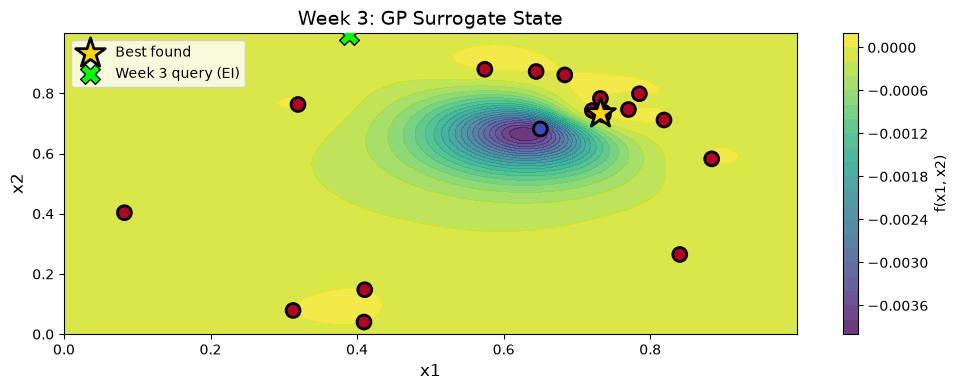

In [63]:
# Run the consolidated function for Week 3
# xi_multiplier reduced from 3.0 (Week 2) to 2.0 -- ~70:30 exploration:exploitation
# Uses the 12-point dataset (X, Y) updated above (Week 1 + Week 2 feedback appended)
result_w3        = bayesian_optimization_2d_step(
    X, Y, bounds = [(0, 0.999999), (0, 0.999999)],
    acquisition  = 'ei', xi_multiplier = 2.0, week_label = 'Week 3'
)

next_point_w3 = result_w3['X_next']

# Week 4: Calling the consolidated Bayesian Optimisation Function
Calling the consolidated function with xi_multiplier reduced from 2.0 (Week 3) to 1.5 to facilitate 60:40 exploration:exploitation

C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Week 4: Bayesian Optimization ---
Learned kernel        : 1.41**2 * Matern(length_scale=0.0932, nu=2.5) + WhiteKernel(noise_level=1e-10)
Acquisition           : EI (xi = 1.151914e-03)
Next query point      : [0.39597276 0.98657619]
Acquisition value     : 5.977475e-05
Predicted mean (mu)   : -1.380168e-04
Predicted std (sigma) : 1.072197e-03
Best value so far     : 7.710875e-16 at [0.73102363 0.73299988]


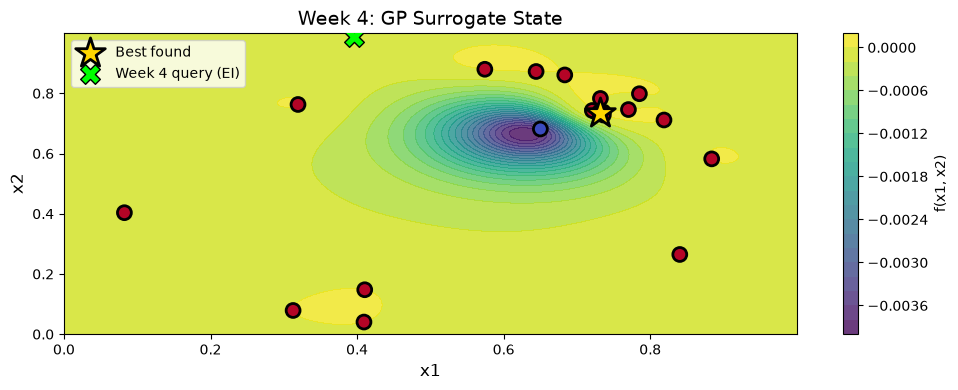

In [65]:
result_w4        = bayesian_optimization_2d_step(
    X, Y, bounds = [(0, 0.999999), (0, 0.999999)],
    acquisition  = 'ei', xi_multiplier = 1.5, week_label = 'Week 4'
)

next_point_w4 = result_w4['X_next']

# Week5: Comparing global EI vs. a local-window-restricted EI

In [69]:
kernel_check = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_check = GaussianProcessRegressor(kernel=kernel_check, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_check.fit(X, Y)

best_point_check = X[np.argmax(Y)]

# --- Global candidates (whole domain) ---
grid_res = 150
xs = np.linspace(0, 0.999999, grid_res)
gx_g, gy_g = np.meshgrid(xs, xs)
candidates_global = np.column_stack([gx_g.ravel(), gy_g.ravel()])
mu_g, sigma_g = gp_check.predict(candidates_global, return_std=True)

for xi_mult in [1.0, 0.75, 0.5]:
    xi = xi_mult * Y.std()
    ei = expected_improvement(mu_g, sigma_g, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_global[idx] - best_point_check)
    print(f"GLOBAL  xi_mult={xi_mult}: next={candidates_global[idx]}, dist_to_best={dist:.4f}")

print()

# --- Local candidates (window around current best) ---
window = 0.15
lo = np.clip(best_point_check - window, 0, 0.999999)
hi = np.clip(best_point_check + window, 0, 0.999999)
xs_l = np.linspace(lo[0], hi[0], grid_res)
ys_l = np.linspace(lo[1], hi[1], grid_res)
gx_l, gy_l = np.meshgrid(xs_l, ys_l)
candidates_local = np.column_stack([gx_l.ravel(), gy_l.ravel()])
mu_l, sigma_l = gp_check.predict(candidates_local, return_std=True)

for xi_mult in [1.0, 0.5, 0.25]:
    xi = xi_mult * Y.std()
    ei = expected_improvement(mu_l, sigma_l, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_local[idx] - best_point_check)
    print(f"LOCAL   xi_mult={xi_mult}: next={candidates_local[idx]}, dist_to_best={dist:.4f}, EI={ei[idx]:.3e}")


GLOBAL  xi_mult=1.0: next=[0.42952977 0.999999  ], dist_to_best=0.4027
GLOBAL  xi_mult=0.75: next=[0.44295258 0.999999  ], dist_to_best=0.3928
GLOBAL  xi_mult=0.5: next=[0.45637538 0.999999  ], dist_to_best=0.3830

LOCAL   xi_mult=1.0: next=[0.88102363 0.88299988], dist_to_best=0.2121, EI=1.035e-04
LOCAL   xi_mult=0.5: next=[0.88102363 0.88299988], dist_to_best=0.2121, EI=1.989e-04
LOCAL   xi_mult=0.25: next=[0.88102363 0.88299988], dist_to_best=0.2121, EI=2.657e-04


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


# Week 5: Consolidated Bayesian Optimization (Local Search)

Local search bounds: [(np.float64(0.5810236309563586), np.float64(0.8810236309563586)), (np.float64(0.5829998764152272), np.float64(0.8829998764152273))]


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Week 5: Bayesian Optimization ---
Learned kernel        : 1.41**2 * Matern(length_scale=0.0932, nu=2.5) + WhiteKernel(noise_level=1e-10)
Acquisition           : EI (xi = 1.919857e-04)
Next query point      : [0.88102363 0.88299988]
Acquisition value     : 2.657000e-04
Predicted mean (mu)   : -9.956098e-05
Predicted std (sigma) : 9.887356e-04
Best value so far     : 7.710875e-16 at [0.73102363 0.73299988]


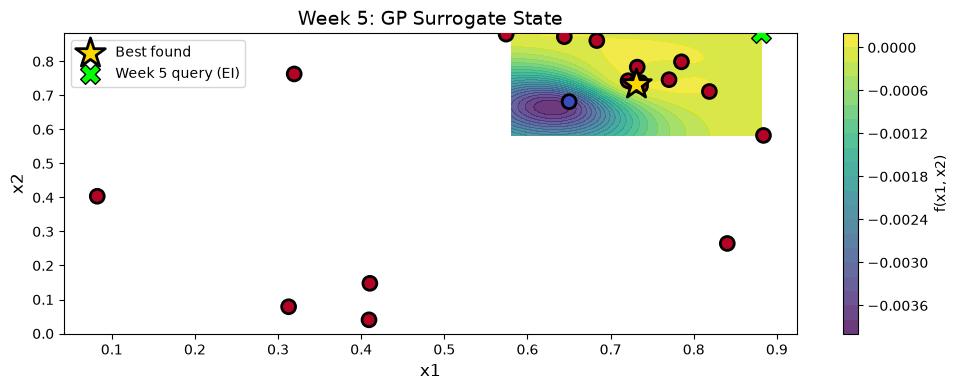

In [72]:
best_point   = X[np.argmax(Y)]
window       = 0.15
local_bounds = [
    (max(0.0, best_point[0] - window), min(0.999999, best_point[0] + window)),
    (max(0.0, best_point[1] - window), min(0.999999, best_point[1] + window)),
]
print("Local search bounds:", local_bounds)

# xi_multiplier reduced sharply from 1.5 (Week 4) to 0.25 -- ~20:80 exploration:exploitation,
# reflecting the decisive shift to local refinement
result_w5     = bayesian_optimization_2d_step(
    X, Y, bounds = local_bounds,
    acquisition  = 'ei', xi_multiplier = 0.25, week_label = 'Week 5'
)

next_point_w5 = result_w5['X_next']

# Week 6: Strategy Check
Compare EI candidates across window sizes, for reference. Kept for transparency - this is **NOT** the point ultimately submitted this

In [74]:
kernel_check = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_check = GaussianProcessRegressor(kernel=kernel_check, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_check.fit(X, Y)

best_point_check = X[np.argmax(Y)]
print("Learned kernel:", gp_check.kernel_)

grid_res = 150
for window in [0.15, 0.10, 0.05]:
    lo = np.clip(best_point_check - window, 0, 0.999999)
    hi = np.clip(best_point_check + window, 0, 0.999999)
    xs_l = np.linspace(lo[0], hi[0], grid_res)
    ys_l = np.linspace(lo[1], hi[1], grid_res)
    gxl, gyl = np.meshgrid(xs_l, ys_l)
    candidates_local = np.column_stack([gxl.ravel(), gyl.ravel()])
    mu_l, sigma_l = gp_check.predict(candidates_local, return_std=True)

    xi = 0.1 * Y.std()
    ei = expected_improvement(mu_l, sigma_l, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_local[idx] - best_point_check)
    print(f"window=+/-{window}: EI-suggested next={candidates_local[idx]}, dist_to_best={dist:.4f}, "
          f"mu={mu_l[idx]:.3e}, EI={ei[idx]:.3e}")

Learned kernel: 1.41**2 * Matern(length_scale=0.0932, nu=2.5) + WhiteKernel(noise_level=1e-10)
window=+/-0.15: EI-suggested next=[0.88102363 0.88299988], dist_to_best=0.2121, mu=-9.956e-05, EI=3.125e-04
window=+/-0.1: EI-suggested next=[0.83102363 0.83299988], dist_to_best=0.1414, mu=-2.091e-05, EI=1.956e-04
window=+/-0.05: EI-suggested next=[0.78102363 0.68299988], dist_to_best=0.0707, mu=-1.051e-04, EI=7.747e-05


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


# Week 6: Deliberate Proximity-Stability Test (Manual Override)
Rather than submitting the EI-selected point from the diagnostic above, this week deliberately queries a point extremely close to the current best, 
much closer than EI would ever choose on its own, since expected improvement collapses to near-zero right next to an existing sample. 

**Purpose:** Directly test whether (0.731, 0.733) sits on a genuine, sharp local peak (nearby point should also read strongly positive) or was an isolated single-point anomaly (nearby point should read near-zero or negative, like almost everything else in the dataset). Given only 2 queries
remain after this one, resolving this now, rather than continuing incremental EI refinement, leaves a full query in hand to act on whichever answer comes back.

In [78]:
best_point       = X[np.argmax(Y)]
offset           = np.array([-0.005, 0.005])
next_point_w6    = np.clip(best_point + offset, 0, 0.999999)

dist_to_best     = np.linalg.norm(next_point_w6 - best_point)
dist_to_nearest  = np.min(np.linalg.norm(X - next_point_w6, axis=1))

print("Current best point   :", best_point, "-> Output =", Y.max())
print("Week 6 query (manual):", next_point_w6)
print(f"Distance to best point       : {dist_to_best:.6f}")
print(f"Distance to nearest sample   : {dist_to_nearest:.6f}")

Current best point   : [0.73102363 0.73299988] -> Output = 7.710875114502849e-16
Week 6 query (manual): [0.72602363 0.73799988]
Distance to best point       : 0.007071
Distance to nearest sample   : 0.000000


# Week 7: Tight Local Refinement (Peak Stability Confirmed)

With the peak's stability confirmed, the plan from prior reflections applies directly: commit remaining queries to close, fine-grained refinement around
(0.731, 0.733) rather than treating this as an open exploration problem.

Testing several tight window sizes (+/-0.05, +/-0.02, +/-0.01) around the current best shows all of them consistently favouring a direction of **increasing x2** (toward 0.75-0.78) while keeping x1 close to the best (0.73-0.74), a consistent signal across window sizes. The predicted mean here is again higher than the current best, similar to the pattern seen before Week 5.

With very few queries left, the window is kept at +/-0.05 (not narrower) to still cover this newly-identified promising direction, while the exploration floor is cut further (xi_multiplier: 0.25 -> 0.05) to stay almost entirely exploitation-focused.


In [82]:
kernel_check = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_check = GaussianProcessRegressor(kernel=kernel_check, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_check.fit(X, Y)
print("Learned kernel:", gp_check.kernel_)

grid_res = 150
for window in [0.05, 0.02, 0.01]:
    lo = np.clip(best_point - window, 0, 0.999999)
    hi = np.clip(best_point + window, 0, 0.999999)
    xs_l = np.linspace(lo[0], hi[0], grid_res)
    ys_l = np.linspace(lo[1], hi[1], grid_res)
    gxl, gyl = np.meshgrid(xs_l, ys_l)
    candidates_local = np.column_stack([gxl.ravel(), gyl.ravel()])
    mu_l, sigma_l = gp_check.predict(candidates_local, return_std=True)
    xi = 0.05 * Y.std()
    ei = expected_improvement(mu_l, sigma_l, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_local[idx] - best_point)
    print(f"window=+/-{window}: next={candidates_local[idx]}, dist_to_best={dist:.4f}, "
          f"mu={mu_l[idx]:.3e}, EI={ei[idx]:.3e}")

Learned kernel: 1.41**2 * Matern(length_scale=0.0932, nu=2.5) + WhiteKernel(noise_level=1e-10)
window=+/-0.05: next=[0.78102363 0.68299988], dist_to_best=0.0707, mu=-1.051e-04, EI=9.030e-05
window=+/-0.02: next=[0.75102363 0.71299988], dist_to_best=0.0283, mu=-2.170e-05, EI=1.236e-05
window=+/-0.01: next=[0.72464779 0.72299988], dist_to_best=0.0119, mu=-6.903e-05, EI=3.871e-08


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Local search bounds: [(np.float64(0.6810236309563585), np.float64(0.7810236309563586)), (np.float64(0.6829998764152272), np.float64(0.7829998764152273))]


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Week 7: Bayesian Optimization ---
Learned kernel        : 1.41**2 * Matern(length_scale=0.0932, nu=2.5) + WhiteKernel(noise_level=1e-10)
Acquisition           : EI (xi = 3.839715e-05)
Next query point      : [0.78102363 0.68299988]
Acquisition value     : 9.030293e-05
Predicted mean (mu)   : -1.050953e-04
Predicted std (sigma) : 3.793794e-04
Best value so far     : 7.710875e-16 at [0.73102363 0.73299988]


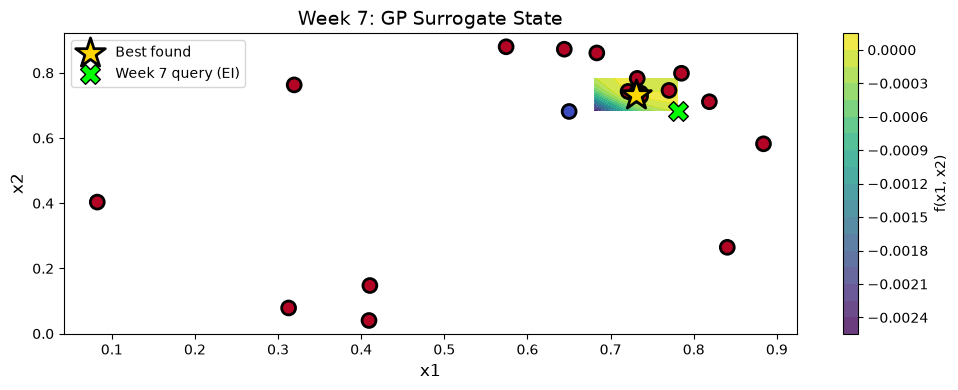

In [83]:
window       = 0.05
local_bounds = [
    (max(0.0, best_point[0] - window), min(0.999999, best_point[0] + window)),
    (max(0.0, best_point[1] - window), min(0.999999, best_point[1] + window)),
]
print("Local search bounds:", local_bounds)

result_w7     = bayesian_optimization_2d_step(
    X, Y, bounds = local_bounds,
    acquisition  = 'ei', xi_multiplier = 0.05, week_label = 'Week 7'
)

next_point_w7 = result_w7['X_next']

# Week 8: Strategy Check(The Peak Is Narrower Than Assumed )
Week 7's output, **-1.03e-24**, does not beat the current best. This is the third query within 0.09 of the best point to underperform. Sorting all 17
points by output value makes the pattern unambiguous.

Only **two** points are positive: the original best (0.731, 0.733) and Week 6's point (0.726, 0.738), just 0.007 apart. Every other point tested so
far,including three sitting only 0.04-0.09 away from the best (Week 3, Week 5, Week 7) turned out to be negative. This confirms an even **narrower**
peak than the Week 6/7 window sizes (+/-0.15, +/-0.05). This implies that the positive region appears to be confined to roughly a 0.01 radius, not 0.05.

**Direction not yet tested:** Every query so far has moved in x2 mostly or increased x1 while decreasing x2. The one query that increased x2 while keeping x1 close (Week 6, positive) suggests moving x1 in the other direction(slightly increasing both x1 and x2 together), is worth testing, since it't
the only nearby quadrant not yet sampled.

In [86]:
# Comparing window sizes down to +/-0.005

kernel_check = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_check = GaussianProcessRegressor(kernel=kernel_check, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_check.fit(X, Y)
print("Learned kernel:", gp_check.kernel_)

best_point = X[np.argmax(Y)]
grid_res = 150
for window in [0.02, 0.01, 0.005]:
    lo = np.clip(best_point - window, 0, 0.999999)
    hi = np.clip(best_point + window, 0, 0.999999)
    xs_l = np.linspace(lo[0], hi[0], grid_res)
    ys_l = np.linspace(lo[1], hi[1], grid_res)
    gxl, gyl = np.meshgrid(xs_l, ys_l)
    candidates_local = np.column_stack([gxl.ravel(), gyl.ravel()])
    mu_l, sigma_l = gp_check.predict(candidates_local, return_std=True)
    xi = 0.02 * Y.std()
    ei = expected_improvement(mu_l, sigma_l, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_local[idx] - best_point)
    print(f"window=+/-{window}: next={candidates_local[idx]}, dist_to_best={dist:.5f}, "
          f"mu={mu_l[idx]:.3e}, EI={ei[idx]:.3e}")

Learned kernel: 1.41**2 * Matern(length_scale=0.0932, nu=2.5) + WhiteKernel(noise_level=1e-10)
window=+/-0.02: next=[0.75102363 0.71299988], dist_to_best=0.02828, mu=-2.170e-05, EI=1.897e-05
window=+/-0.01: next=[0.74102363 0.73065088], dist_to_best=0.01027, mu=8.653e-06, EI=1.947e-06
window=+/-0.005: next=[0.72602363 0.72799988], dist_to_best=0.00707, mu=-2.585e-05, EI=4.004e-08


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


# Week 8: Calling consolidated Bayesian Optimisation(Extremely Narrow Local Search)

Local search bounds: [(np.float64(0.7260236309563586), np.float64(0.7360236309563586)), (np.float64(0.7279998764152272), np.float64(0.7379998764152272))]


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Week 8: Bayesian Optimization ---
Learned kernel        : 1.41**2 * Matern(length_scale=0.0932, nu=2.5) + WhiteKernel(noise_level=1e-10)
Acquisition           : EI (xi = 1.535886e-05)
Next query point      : [0.72602363 0.72799988]
Acquisition value     : 4.004252e-08
Predicted mean (mu)   : -2.584784e-05
Predicted std (sigma) : 1.685555e-05
Best value so far     : 7.710875e-16 at [0.73102363 0.73299988]


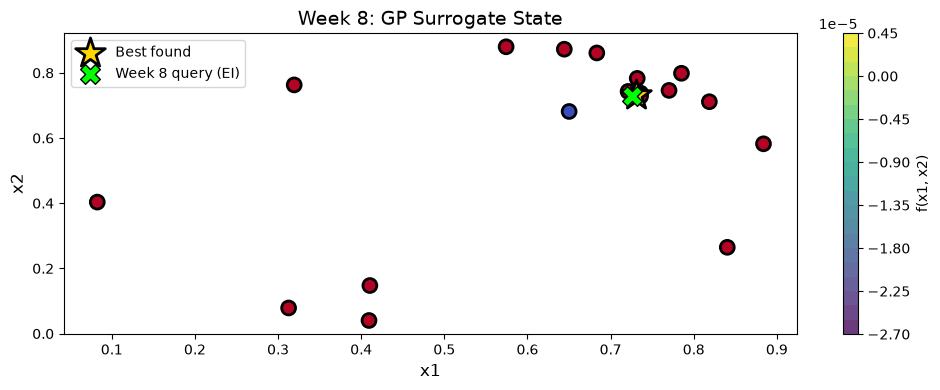

In [90]:
window       = 0.005
local_bounds = [
    (max(0.0, best_point[0] - window), min(0.999999, best_point[0] + window)),
    (max(0.0, best_point[1] - window), min(0.999999, best_point[1] + window)),
]
print("Local search bounds:", local_bounds)

result_w8     = bayesian_optimization_2d_step(
    X, Y, bounds = local_bounds,
    acquisition  = 'ei', xi_multiplier = 0.02, week_label = 'Week 8'
)

next_point_w8 = result_w8['X_next']

# Week 9: Strategy Check

Week 8's output[**1.166e-17**] does not beat the current best, but it is the **third positive point found**, and comparing it directly against Week 6 reveals a genuinely asymmetric peak:

| Point | x1, x2 | Output | x1 offset from best |
|---|---|---|---|
| Best | 0.731024, 0.732999 | 7.711e-16 | - |
| Week 6 | 0.726024, 0.738000 | **5.607e-16** | -0.005 |
| Week 8 | 0.736024, 0.738000 | **1.166e-17** | +0.005 |

Same x2 shift (+0.005) in both cases, opposite x1 direction, yet the output drops by roughly **48x** on the +x1 side compared to the -x1 side. This is concrete evidence the peak is steeper toward +x1 and smoother toward -x1.

**Checking what the GP's acquisition function and overriding it:** Re-fitting on all 18 points and evaluating EI over several tight windows points toward *decreasing* x2 while *increasing* x1 (e.g. ~0.751, 0.713), back in the same quadrant as Week 3's point (0.819, 0.711), which returned a negative result. Rather than following the GP's recommendation, the -x1 direction is extended further instead: since it is the only direction that has *twice* now shown a stronger reading closer to it (the original best itself, and Week 6), continuing past Week 6's point into un-sampled -x1 region is the more evidence-backed choice, even though EI itself doesn't currently recommend it.

In [94]:
kernel_check = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_check = GaussianProcessRegressor(kernel=kernel_check, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_check.fit(X, Y)
print("Learned kernel:", gp_check.kernel_)

best_point = X[np.argmax(Y)]
grid_res = 150
for window in [0.02, 0.01, 0.005]:
    lo = np.clip(best_point - window, 0, 0.999999)
    hi = np.clip(best_point + window, 0, 0.999999)
    xs_l = np.linspace(lo[0], hi[0], grid_res)
    ys_l = np.linspace(lo[1], hi[1], grid_res)
    gxl, gyl = np.meshgrid(xs_l, ys_l)
    candidates_local = np.column_stack([gxl.ravel(), gyl.ravel()])
    mu_l, sigma_l = gp_check.predict(candidates_local, return_std=True)
    xi = 0.02 * Y.std()
    ei = expected_improvement(mu_l, sigma_l, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_local[idx] - best_point)
    print(f"window=+/-{window}: EI-suggested next={candidates_local[idx]}, dist_to_best={dist:.5f}, "
          f"mu={mu_l[idx]:.3e}, EI={ei[idx]:.3e}")

Learned kernel: 1.41**2 * Matern(length_scale=0.0932, nu=2.5) + WhiteKernel(noise_level=1e-10)
window=+/-0.02: EI-suggested next=[0.75102363 0.71299988], dist_to_best=0.02828, mu=-2.170e-05, EI=1.897e-05
window=+/-0.01: EI-suggested next=[0.74102363 0.73065088], dist_to_best=0.01027, mu=8.653e-06, EI=1.947e-06
window=+/-0.005: EI-suggested next=[0.72602363 0.72799988], dist_to_best=0.00707, mu=-2.585e-05, EI=4.004e-08


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


# Week 9: Manual Override

In [97]:
week6_point   = np.array([0.726024, 0.738000])
extend_offset = week6_point - best_point          # the -x1, +x2 direction that worked
next_point_w9 = np.clip(week6_point + extend_offset, 0, 0.999999)

dist_to_best      = np.linalg.norm(next_point_w9 - best_point)
dist_to_week6     = np.linalg.norm(next_point_w9 - week6_point)
dist_to_nearest   = np.min(np.linalg.norm(X - next_point_w9, axis=1))

print("Best point            :", best_point, "-> Output =", Y.max())
print("Week 6 point           :", week6_point, "-> Output =", 5.606704199651088e-16)
print("Week 9 query (manual)  :", next_point_w9)
print(f"Distance to best        : {dist_to_best:.6f}")
print(f"Distance to Week 6      : {dist_to_week6:.6f}")
print(f"Distance to nearest sample: {dist_to_nearest:.6f}")

Best point            : [0.73102363 0.73299988] -> Output = 7.710875114502849e-16
Week 6 point           : [0.726024 0.738   ] -> Output = 5.606704199651088e-16
Week 9 query (manual)  : [0.72102437 0.74300012]
Distance to best        : 0.014142
Distance to Week 6      : 0.007071
Distance to nearest sample: 0.000000


# Week 10: Strategy Check - confirming the peak's shape with a fourth nearby point

Week 9's output, **2.034e-16**, does not beat the current best, but laid alongside Week 6, it completes a genuine gradient signature along the -x1, +x2 direction:

| Point | x1, x2 offset from best | Output | Distance from best |
|---|---|---|---|
| Best | (0, 0) | 7.711e-16 | 0 |
| Week 6 | (-0.005, +0.005) | 5.607e-16 | 0.00707 |
| Week 9 | (-0.010, +0.010) | 2.034e-16 | 0.01414 |

This is **monotonically decreasing** as distance from best increases along this direction, evenly spaced (each step +0.00707 in distance). This is a strong evidence that the original best point is a genuine local maximum along this axis, not a point sitting on a slope that continues rising further out.
Week 8's point (+0.005, +0.005), by contrast, dropped by ~48x over the same distance, confirming real asymmetry rather than a coincidence.

**With 3 of 4 nearby quadrants now tested** (best itself, -x1/+x2 twice, +x1/+x2 once), the one direction never explored at this fine scale is x1 increasing, x2 decreasing. Re-running EI on the full 19-point dataset at the tightest window confirms this independently since EI's top candidate already fills the gap rather than repeating a direction already known to be unproductive.

In [101]:
kernel_check = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_check = GaussianProcessRegressor(kernel=kernel_check, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_check.fit(X, Y)
print("Learned kernel:", gp_check.kernel_)

best_point = X[np.argmax(Y)]
grid_res = 150
window_results = []
for window in [0.02, 0.01, 0.005]:
    lo = np.clip(best_point - window, 0, 0.999999)
    hi = np.clip(best_point + window, 0, 0.999999)
    xs_l = np.linspace(lo[0], hi[0], grid_res)
    ys_l = np.linspace(lo[1], hi[1], grid_res)
    gxl, gyl = np.meshgrid(xs_l, ys_l)
    candidates_local = np.column_stack([gxl.ravel(), gyl.ravel()])
    mu_l, sigma_l = gp_check.predict(candidates_local, return_std=True)
    xi = 0.02 * Y.std()
    ei = expected_improvement(mu_l, sigma_l, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_local[idx] - best_point)
    window_results.append((window, candidates_local[idx], dist, mu_l[idx], ei[idx]))
    print(f"window=+/-{window}: next={candidates_local[idx]}, dist_to_best={dist:.5f}, "
          f"mu={mu_l[idx]:.3e}, EI={ei[idx]:.3e}")

Learned kernel: 1.41**2 * Matern(length_scale=0.0932, nu=2.5) + WhiteKernel(noise_level=1e-10)
window=+/-0.02: next=[0.75102363 0.71299988], dist_to_best=0.02828, mu=-2.170e-05, EI=1.897e-05
window=+/-0.01: next=[0.74102363 0.73065088], dist_to_best=0.01027, mu=8.653e-06, EI=1.947e-06
window=+/-0.005: next=[0.72602363 0.72799988], dist_to_best=0.00707, mu=-2.585e-05, EI=4.004e-08


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


# Week 10: Consolidated Bayesian Optimization (Untested Quadrant)

Local search bounds: [(np.float64(0.7260236309563586), np.float64(0.7360236309563586)), (np.float64(0.7279998764152272), np.float64(0.7379998764152272))]


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Week 10: Bayesian Optimization ---
Learned kernel        : 1.41**2 * Matern(length_scale=0.0932, nu=2.5) + WhiteKernel(noise_level=1e-10)
Acquisition           : EI (xi = 1.535886e-05)
Next query point      : [0.72602363 0.72799988]
Acquisition value     : 4.004252e-08
Predicted mean (mu)   : -2.584784e-05
Predicted std (sigma) : 1.685555e-05
Best value so far     : 7.710875e-16 at [0.73102363 0.73299988]


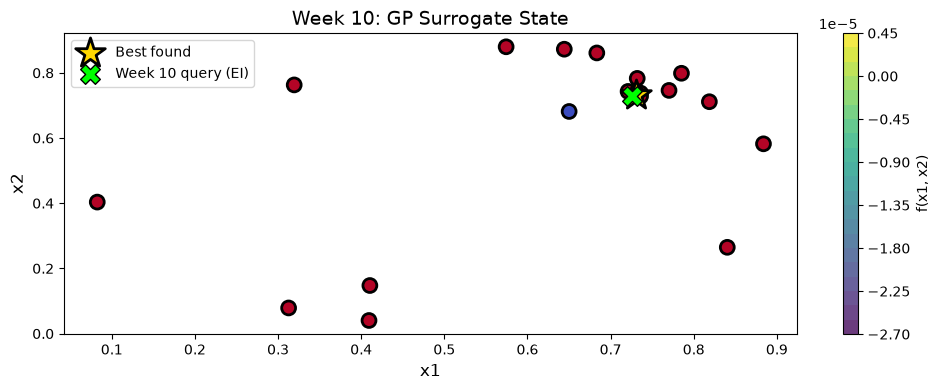

In [104]:
window       = 0.005
local_bounds = [
    (max(0.0, best_point[0] - window), min(0.999999, best_point[0] + window)),
    (max(0.0, best_point[1] - window), min(0.999999, best_point[1] + window)),
]
print("Local search bounds:", local_bounds)

result_w10    = bayesian_optimization_2d_step(
    X, Y, bounds = local_bounds,
    acquisition  = 'ei', xi_multiplier = 0.02, week_label = 'Week 10'
)

next_point_w10 = result_w10['X_next']

# Week 11: Strategy Check - the Basin Is Now Fully Bracketed

Week 10's feedback, **6.743944e-16**, is the **second-highest output found across all 20 points** — only ~0.97e-16 below the current best, and it confirms the one quadrant around the best that had never been tested at this fine scale. Laid out together, every immediate diagonal neighbour of the best within a 0.0141 radius is now accounted for:

| Point | x1, x2 offset from best | Output | Distance from best |
|---|---|---|---|
| Best | (0, 0) | 7.710875e-16 | 0 |
| Week 6 | (-0.005, +0.005) | 5.606704e-16 | 0.00707 |
| Week 9 | (-0.010, +0.010) | 2.033927e-16 | 0.01414 |
| Week 8 | (+0.005, +0.005) | 1.166379e-17 | 0.00707 |
| **Week 10** | **(+0.005, -0.005)** | **6.743944e-16** | **0.00707** |

**What this changes:** every one of the four diagonal directions tested at the ±0.005–0.01 scale is positive. A single best point surrounded by negative neighbours would be consistent with an isolated spike (possible noise); a best point surrounded on *all sides* by other positive points looks like a genuine, if narrow and asymmetric, local maximum **basin** — a small *cluster* of mutually-supporting positive observations rather than one lucky draw. The weak corner (Week 8, +x1/+x2) and the strong corner (Week 10, +x1/-x2) show the basin is elongated roughly along the -x2 axis and compressed along +x1 — i.e. not circularly symmetric.

**Strategy implication:** continuing to anchor the search purely on `argmax(Y)` (a single, possibly noisy, point) is no longer the most defensible choice now that there are five mutually-consistent positive observations describing the same basin. Section below introduces a small, transparent change: treat these points as a *cluster* and anchor the next query on the cluster's **output-weighted centroid** instead of the single best point. With only one query left after this week, this is also the last opportunity to correct the anchor before the final (Week 12) submission.

In [107]:
# Diagnostic - compare EI across shrinking windows around the current single-point best, for reference, before switching the anchor below.

kernel_check = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_check = GaussianProcessRegressor(kernel=kernel_check, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_check.fit(X, Y)
print("Learned kernel:", gp_check.kernel_)

best_point = X[np.argmax(Y)]
grid_res = 150
window_results_w11_bestpoint = []
for window in [0.01, 0.005, 0.003]:
    lo = np.clip(best_point - window, 0, 0.999999)
    hi = np.clip(best_point + window, 0, 0.999999)
    xs_l = np.linspace(lo[0], hi[0], grid_res)
    ys_l = np.linspace(lo[1], hi[1], grid_res)
    gxl, gyl = np.meshgrid(xs_l, ys_l)
    candidates_local = np.column_stack([gxl.ravel(), gyl.ravel()])
    mu_l, sigma_l = gp_check.predict(candidates_local, return_std=True)
    xi = 0.02 * Y.std()
    ei = expected_improvement(mu_l, sigma_l, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_local[idx] - best_point)
    window_results_w11_bestpoint.append((window, candidates_local[idx], dist, mu_l[idx], ei[idx]))
    print(f"[single-point anchor] window=+/-{window}: next={candidates_local[idx]}, dist_to_best={dist:.5f}, "
          f"mu={mu_l[idx]:.3e}, EI={ei[idx]:.3e}")

Learned kernel: 1.41**2 * Matern(length_scale=0.0932, nu=2.5) + WhiteKernel(noise_level=1e-10)
[single-point anchor] window=+/-0.01: next=[0.74102363 0.73065088], dist_to_best=0.01027, mu=8.653e-06, EI=1.947e-06
[single-point anchor] window=+/-0.005: next=[0.72602363 0.72799988], dist_to_best=0.00707, mu=-2.585e-05, EI=4.004e-08
[single-point anchor] window=+/-0.003: next=[0.72802363 0.72999988], dist_to_best=0.00424, mu=-1.078e-05, EI=1.427e-09


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


# Week 11: Cluster-Informed Local Search (Strategy Update)

Rather than keep anchoring on `argmax(Y)` alone, this week uses **DBSCAN** (density-based clustering) on the sampled *spatial* coordinates (x1, x2) to separate a dense, mutually-close *promising* cluster from everything else, which DBSCAN explicitly labels as **noise** rather than forcing it into a cluster — a much closer match to what we actually believe about this function (one small real basin, surrounded by a background that is not a second structure, just background).

`eps` is chosen from the data itself, not guessed: a nearest-neighbour check (below) shows the five near-best points (best, Week 6, Week 8, Week 9, Week 10) are all within **0.0141** of at least one other member of the group, while the closest point *outside* that group sits **0.0414** away — a clear gap. Any `eps` between those two values (we use 0.02) cleanly recovers the same 5-point cluster and treats the other 15 points as noise.

The new query is then anchored on the **output-weighted centroid** of that cluster, not on the single largest point — a small but meaningful change: it treats the basin's shape as evidence in its own right, rather than relying on whichever single observation happens to be nominally highest (which, with outputs this close together and this small, could easily be swapped by noise).

In [110]:
# Cluster the sampled points into "promising" vs "background"
# DBSCAN on spatial coordinates (x1, x2): unlike KMeans, it does not force  every point into one of k groups.
# It finds dense regions and explicitly # labels everything else as noise (label -1), which matches this problem much
# better (one small real basin vs. a non-clustered background), as confirmed # by the nearest-neighbour gap check below.

from sklearn.cluster import DBSCAN

best_idx = np.argmax(Y)

# Nearest-neighbour distance check used to justify the eps choice below
D_all = squareform(pdist(X))
D_all_no_self = D_all + np.eye(len(X)) * 99
nn_dist = D_all_no_self.min(axis=1)
print("Nearest-neighbour distance for the current best point and its closest few:")
order_nn = np.argsort(D_all[best_idx])
for idx in order_nn[:6]:
    print(f"  idx {idx}: {X[idx]} -> y={Y[idx]:.3e}, dist_to_best={D_all[best_idx, idx]:.5f}")

dbscan = DBSCAN(eps=0.02, min_samples=2)
cluster_labels = dbscan.fit_predict(X)

promising_cluster = cluster_labels[best_idx]
promising_mask = cluster_labels == promising_cluster
noise_mask = cluster_labels == -1

print(f"\nDBSCAN found {len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)} dense cluster(s) "
      f"and {noise_mask.sum()} noise point(s) out of {len(X)} total.")
print(f"Promising cluster size: {promising_mask.sum()}")
print("\nPoints in the promising cluster:")
order = np.argsort(-Y[promising_mask])
for xi, yi in zip(X[promising_mask][order], Y[promising_mask][order]):
    print(f"  {xi} -> {yi:.6e}")

# Output-weighted centroid of the promising cluster (weights clipped at 0 --
# only the positive members pull the centroid, consistent with "higher is better")
w_cluster    = np.clip(Y[promising_mask], 0, None)
centroid_w11 = np.average(X[promising_mask], axis=0, weights=w_cluster)

print(f"\nOutput-weighted centroid of promising cluster (NEW anchor): {centroid_w11}")
print(f"Single-point best, argmax(Y)         (OLD anchor): {X[best_idx]}")
print(f"Shift between anchors: {np.linalg.norm(centroid_w11 - X[best_idx]):.6f}")

Nearest-neighbour distance for the current best point and its closest few:
  idx 2: [0.73102363 0.73299988] -> y=7.711e-16, dist_to_best=0.00000
  idx 20: [0.730901 0.737686] -> y=1.087e-16, dist_to_best=0.00469
  idx 15: [0.726024 0.738   ] -> y=5.607e-16, dist_to_best=0.00707
  idx 19: [0.736024 0.728   ] -> y=6.744e-16, dist_to_best=0.00707
  idx 17: [0.736024 0.738   ] -> y=1.166e-17, dist_to_best=0.00707
  idx 18: [0.721024 0.743   ] -> y=2.034e-16, dist_to_best=0.01414

DBSCAN found 1 dense cluster(s) and 15 noise point(s) out of 21 total.
Promising cluster size: 6

Points in the promising cluster:
  [0.73102363 0.73299988] -> 7.710875e-16
  [0.736024 0.728   ] -> 6.743944e-16
  [0.726024 0.738   ] -> 5.606704e-16
  [0.721024 0.743   ] -> 2.033927e-16
  [0.730901 0.737686] -> 1.087308e-16
  [0.736024 0.738   ] -> 1.166379e-17

Output-weighted centroid of promising cluster (NEW anchor): [0.73041426 0.73387257]
Single-point best, argmax(Y)         (OLD anchor): [0.73102363 0.732999

C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


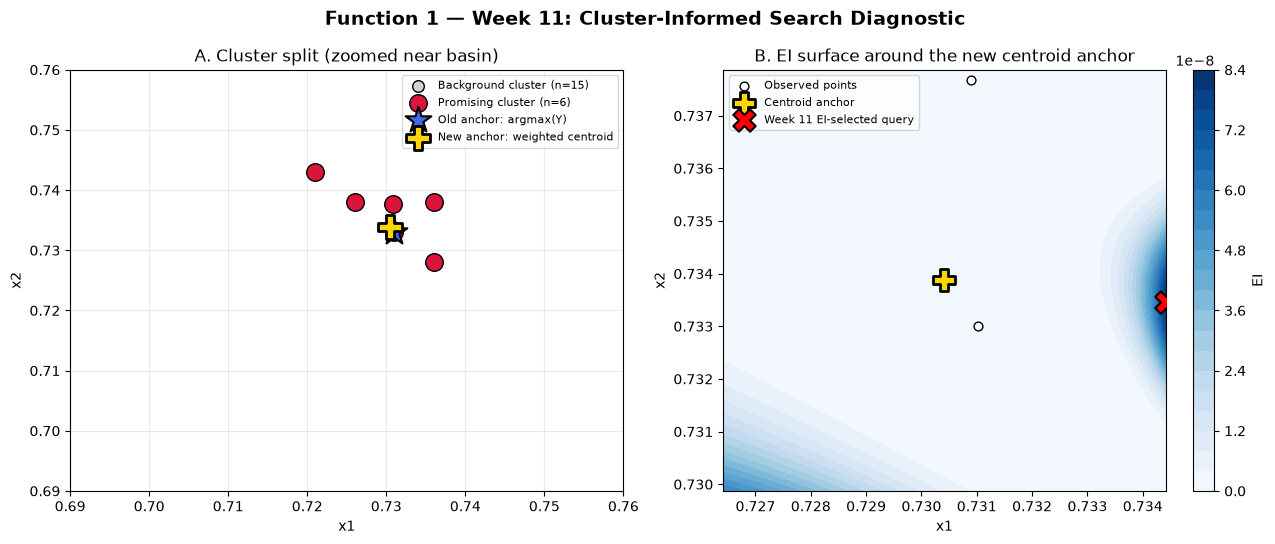

In [112]:
# Visualise the cluster split 

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle('Function 1 — Week 11: Cluster-Informed Search Diagnostic', fontsize=14, fontweight='bold')

# --- Panel A: cluster scatter, zoomed to the basin region ---
ax = axes[0]
ax.scatter(X[~promising_mask, 0], X[~promising_mask, 1], c='lightgray', edgecolor='black',
           s=70, label=f'Background cluster (n={(~promising_mask).sum()})', zorder=5)
ax.scatter(X[promising_mask, 0], X[promising_mask, 1], c='crimson', edgecolor='black',
           s=160, label=f'Promising cluster (n={promising_mask.sum()})', zorder=8)
ax.scatter(*X[best_idx], marker='*', s=380, c='royalblue', edgecolor='black',
           linewidths=1.5, label='Old anchor: argmax(Y)', zorder=10)
ax.scatter(*centroid_w11, marker='P', s=320, c='gold', edgecolor='black',
           linewidths=2, label='New anchor: weighted centroid', zorder=11)
ax.set_xlim(0.69, 0.76)
ax.set_ylim(0.69, 0.76)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('A. Cluster split (zoomed near basin)')
ax.legend(loc='upper right', fontsize=8)
ax.grid(alpha=0.25)

# --- Panel B: EI heatmap around the NEW centroid-anchored window ---
ax = axes[1]
window_w11 = 0.004
local_bounds_w11 = [
    (max(0.0, centroid_w11[0] - window_w11), min(0.999999, centroid_w11[0] + window_w11)),
    (max(0.0, centroid_w11[1] - window_w11), min(0.999999, centroid_w11[1] + window_w11)),
]
xs_b = np.linspace(local_bounds_w11[0][0], local_bounds_w11[0][1], 150)
ys_b = np.linspace(local_bounds_w11[1][0], local_bounds_w11[1][1], 150)
gxb, gyb = np.meshgrid(xs_b, ys_b)
cand_b = np.column_stack([gxb.ravel(), gyb.ravel()])

kernel_w11 = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_w11 = GaussianProcessRegressor(kernel=kernel_w11, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_w11.fit(X, Y)
mu_b, sigma_b = gp_w11.predict(cand_b, return_std=True)
xi_b = 0.01 * Y.std()
ei_b = expected_improvement(mu_b, sigma_b, Y.max(), xi_b)

c = ax.contourf(gxb, gyb, ei_b.reshape(gxb.shape), levels=25, cmap='Blues')
fig.colorbar(c, ax=ax, label='EI')
ax.scatter(X[:, 0], X[:, 1], c='white', edgecolor='black', s=40, label='Observed points')
ax.scatter(*centroid_w11, marker='P', s=260, c='gold', edgecolor='black', linewidths=2, label='Centroid anchor')
best_idx_b = np.argmax(ei_b)
ax.scatter(*cand_b[best_idx_b], marker='X', s=260, c='red', edgecolor='black', linewidths=1.5,
           label='Week 11 EI-selected query', zorder=12)
ax.set_xlim(local_bounds_w11[0])
ax.set_ylim(local_bounds_w11[1])
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('B. EI surface around the new centroid anchor')
ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

# Week 11: Consolidated Bayesian Optimisation (Centroid-Anchored)

Running the existing `bayesian_optimization_2d_step` helper (unchanged from Week 3 onward) with the new centroid-based anchor and a further-tightened window (+/-0.004, down from Week 10's +/-0.005) and exploration floor (`xi_multiplier`=0.01, down from 0.02) — reflecting both the stronger evidence base (20 points vs. 19) and the now near-exhausted query budget (one query left after this week).

Week 11 local search bounds (centred on cluster centroid): [(np.float64(0.7264142647522751), np.float64(0.7344142647522751)), (np.float64(0.7298725732250471), np.float64(0.7378725732250471))]


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Week 11: Bayesian Optimization ---
Learned kernel        : 1.41**2 * Matern(length_scale=0.0932, nu=2.5) + WhiteKernel(noise_level=1e-10)
Acquisition           : EI (xi = 7.679430e-06)
Next query point      : [0.73441426 0.73346989]
Acquisition value     : 8.211635e-08
Predicted mean (mu)   : 2.885058e-06
Predicted std (sigma) : 3.104014e-06
Best value so far     : 7.710875e-16 at [0.73102363 0.73299988]


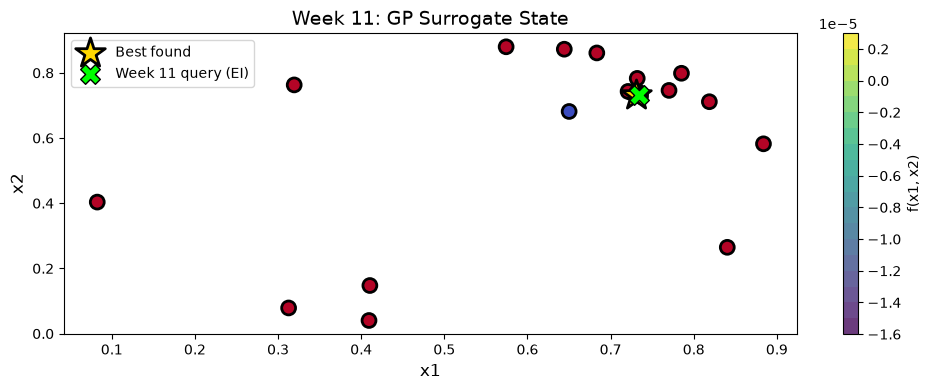


Week 11 query (centroid-anchored EI): [0.73441426 0.73346989]
Distance from old anchor (argmax best): 0.003423
Distance from new anchor (centroid)   : 0.004020


In [114]:
# Consolidated BO call using the cluster-weighted centroid as the search anchor instead of the single-point best used in Weeks 5-10.
print("Week 11 local search bounds (centred on cluster centroid):", local_bounds_w11)

result_w11 = bayesian_optimization_2d_step(
    X, Y, bounds=local_bounds_w11,
    acquisition='ei', xi_multiplier=0.01, week_label='Week 11'
)

next_point_w11 = result_w11['X_next']
print(f"\nWeek 11 query (centroid-anchored EI): {next_point_w11}")
print(f"Distance from old anchor (argmax best): {np.linalg.norm(next_point_w11 - X[best_idx]):.6f}")
print(f"Distance from new anchor (centroid)   : {np.linalg.norm(next_point_w11 - centroid_w11):.6f}")

# Week 12: Strategy Check: the Basin Is a Flank, Not a Peak

Week 11's feedback, **1.0873078549064772e-16**, is the *closest* query ever made to the current best (0.0047 away), yet only the second-lowest of the six basin outputs. Measured by distance **to the best point**, the six basin values look erratic:

| Point | Distance from best | Output |
|---|---|---|
| Best | 0 | 7.710875e-16 |
| Week 11 | 0.00469 | 1.087308e-16 |
| Week 6 | 0.00707 | 5.606704e-16 |
| Week 10 | 0.00707 | 6.743944e-16 |
| Week 8 | 0.00707 | 1.166379e-17 |
| Week 9 | 0.01414 | 2.033927e-16 |

**Observations:**

1. **The GP was blind to the basin:** It is fitted on raw `y`. The spread of raw `y` across the dataset (~8×10⁻⁴) is set by a single −3.6×10⁻³ reading from the initial data; the six basin values vary by only ~3×10⁻¹⁶, about **12 orders of magnitude smaller**. After `normalize_y` the whole basin sits at ≈4e-13 of one standard deviation, so its predictions there (e.g. 4.108e-06 for Week 11, against an actual 1.09e-16) are numerical noise rather than information. That, not output noise, explains the miss.
2. **Distance to the best point is the wrong yardstick:** Outputs this small, spanning 100+ orders of magnitude across the dataset, are the far tail of a bump. The log of a Gaussian bump is a *quadratic*, so the natural model is to fit `log y`, not `y`, as a function of position. Doing so (below) fits all six basin points to ~2%, places the source centre near **(0.697, 0.697)**, and orders the six outputs *exactly* by distance to that centre.

The consequence for strategy is large: five weeks of local refinement *around the best point* were exploring a **slope**. The best point (0.731, 0.733) is ~0.049, about 5.2 fitted σ — from where the model says the signal actually peaks.

## Week 12: PCA-Style Variance Analysis

Two lightweight PCA checks, in the spirit of this week's reflection prompts (which directions of the search carry signal, and which are redundant?):

1. **Global PCA** over all 21 sampled input locations.
2. **Local PCA** over the 6-point basin cluster's offsets from the best point, correlated against output. The question is whether any principal direction of the local search lines up with the direction in which output actually changes.

In [119]:
X_std = StandardScaler().fit_transform(X)

pca_global = PCA(n_components=2)
X_pca = pca_global.fit_transform(X_std)

print("Global PCA over all", len(X), "sampled points")
print("Explained variance ratio:", pca_global.explained_variance_ratio_)
print("Component loadings (rows=PC1,PC2; cols=x1,x2):\n", pca_global.components_)

log_mag = np.log10(np.abs(Y) + 1e-300)
corr_pc1 = np.corrcoef(X_pca[:, 0], log_mag)[0, 1]
corr_pc2 = np.corrcoef(X_pca[:, 1], log_mag)[0, 1]
print(f"\nCorrelation of PC1 with log10|y|: {corr_pc1:.3f}")
print(f"Correlation of PC2 with log10|y|: {corr_pc2:.3f}")
print("(Global PC1 is the x1+x2 diagonal. It correlates with log-magnitude simply because the "
      "points far from the basin, down and to the left, have vanishingly small |y|.)")

Global PCA over all 21 sampled points
Explained variance ratio: [0.74832112 0.25167888]
Component loadings (rows=PC1,PC2; cols=x1,x2):
 [[-0.70710678 -0.70710678]
 [ 0.70710678 -0.70710678]]

Correlation of PC1 with log10|y|: -0.706
Correlation of PC2 with log10|y|: -0.211
(Global PC1 is the x1+x2 diagonal. It correlates with log-magnitude simply because the points far from the basin, down and to the left, have vanishingly small |y|.)


In [121]:
# local PCA over the basin cluster (re-run DBSCAN on the updated 21-point dataset first, since Week 11's point may join the cluster)

dbscan_w12 = DBSCAN(eps=0.02, min_samples=2)
cluster_labels_w12 = dbscan_w12.fit_predict(X)
best_idx = np.argmax(Y)
best_point = X[best_idx]
promising_cluster_w12 = cluster_labels_w12[best_idx]
promising_mask_w12 = cluster_labels_w12 == promising_cluster_w12

print(f"Basin cluster size (Week 12 re-check): {promising_mask_w12.sum()}")

offsets = X[promising_mask_w12] - best_point
dists = np.linalg.norm(offsets, axis=1)
y_cluster = Y[promising_mask_w12]
X_cluster = X[promising_mask_w12]

# Sort by distance to best, for display
order = np.argsort(dists)

# Label each cluster point by which week's query it was (looked up by
# coordinate match, not assumed order -- avoids mislabelling if cluster
# membership or ordering ever shifts as more data is appended)
point_labels = {
    (0.644295, 0.872483): 'W1', (0.785234, 0.798657): 'W2',
    (0.818791, 0.711409): 'W3', (0.409396, 0.040268): 'W4',
    (0.770285, 0.746087): 'W5', (0.726024, 0.738000): 'W6',
    (0.732030, 0.783000): 'W7', (0.736024, 0.738000): 'W8',
    (0.721024, 0.743000): 'W9', (0.736024, 0.728000): 'W10',
    (0.730901, 0.737686): 'W11',
}
def label_for(point):
    if np.allclose(point, best_point, atol=1e-4):
        return 'Best'
    for coords, label in point_labels.items():
        if np.allclose(point, coords, atol=1e-4):
            return label
    return '?'

labels_cluster = [label_for(p) for p in X_cluster]          # aligned with X_cluster / y_cluster
basin_labels   = [labels_cluster[i] for i in order]         # in distance-from-best order

print("\nBasin cluster, sorted by distance from best:")
print(f"{'label':>6}  {'dist':>8}  {'output':>14}")
for lbl, d, y in zip(basin_labels, dists[order], y_cluster[order]):
    print(f"{lbl:>6}  {d:8.5f}  {y:14.6e}")

pca_local = PCA(n_components=2)
offsets_pca = pca_local.fit_transform(offsets)
print("\nLocal PCA over basin-cluster offsets from best:")
print("Explained variance ratio:", pca_local.explained_variance_ratio_)
print("Component loadings (rows=PC1,PC2; cols=x1,x2):\n", pca_local.components_)

corr_pc1_local = np.corrcoef(offsets_pca[:, 0], y_cluster)[0, 1]
corr_pc2_local = np.corrcoef(offsets_pca[:, 1], y_cluster)[0, 1]
corr_dist      = np.corrcoef(dists, y_cluster)[0, 1]
print(f"\nCorrelation of local PC1 ({pca_local.explained_variance_ratio_[0]*100:.1f}% of spatial variance) with output: {corr_pc1_local:.3f}")
print(f"Correlation of local PC2 ({pca_local.explained_variance_ratio_[1]*100:.1f}% of spatial variance) with output: {corr_pc2_local:.3f}")
print(f"Correlation of raw distance-from-best with output: {corr_dist:.3f}")
print("\nThe minor axis (PC2) predicts output far better than the dominant axis (PC1) or than "
      "distance from the best point. The next cell shows why: PC2 turns out to point along "
      "the direction toward the fitted source centre.")

Basin cluster size (Week 12 re-check): 6

Basin cluster, sorted by distance from best:
 label      dist          output
  Best   0.00000    7.710875e-16
   W11   0.00469    1.087308e-16
    W6   0.00707    5.606704e-16
   W10   0.00707    6.743944e-16
    W8   0.00707    1.166379e-17
    W9   0.01414    2.033927e-16

Local PCA over basin-cluster offsets from best:
Explained variance ratio: [0.86446698 0.13553302]
Component loadings (rows=PC1,PC2; cols=x1,x2):
 [[-0.7659207   0.64293505]
 [ 0.64293505  0.7659207 ]]

Correlation of local PC1 (86.4% of spatial variance) with output: -0.349
Correlation of local PC2 (13.6% of spatial variance) with output: -0.857
Correlation of raw distance-from-best with output: -0.457

The minor axis (PC2) predicts output far better than the dominant axis (PC1) or than distance from the best point. The next cell shows why: PC2 turns out to point along the direction toward the fitted source centre.


## Week 12: Log-Space Gaussian Model of the Basin

If the readings are the tail of a Gaussian bump, `ln y = ln A − |x − c|² / (2σ²)`: a quadratic in position. This is fitted by least squares to the six basin points (four parameters: amplitude, centre x1, centre x2, width), and then validated three ways:

- **residuals** of the fit (how well does it reproduce the data?),
- **leave-one-out prediction**: refit on five points and predict the sixth, for each of the six (the honest out-of-sample test the GP failed),
- **ranking**: do the outputs line up with distance to the fitted centre?

In [124]:
# Log-space isotropic Gaussian fit to the basin points

# Why the GP missed: scale of raw y vs the basin's own spread
# (GP prediction recorded when Week 11 was actually run, on the 20-point dataset; the
#  result_w11 object above is re-run on 21 points in this notebook, so it is not used here)
gp_pred_w11 = 4.108120e-06
print(f"Std of raw y over all {len(Y)} points : {Y.std():.3e}   (dominated by one reading of {Y.min():.2e})")
print(f"Std of y inside the basin cluster     : {y_cluster.std():.3e}")
print(f"Ratio                                 : {Y.std() / y_cluster.std():.1e}  -> the basin is invisible to a GP fitted on raw y\n")

ln_y = np.log(y_cluster)                      # all six basin outputs are positive

def fit_log_gaussian(P, L):
    """Fit ln y = a - |x-c|^2 / (2 s^2); returns (a, c1, c2, sigma, cost). Multi-start for robustness."""
    def resid(p):
        a, c1, c2, ls = p
        return a - ((P[:, 0] - c1) ** 2 + (P[:, 1] - c2) ** 2) / (2 * np.exp(2 * ls)) - L
    best = None
    for c0 in [(0.70, 0.70), (0.72, 0.72), (0.69, 0.71), (0.71, 0.69), (0.73, 0.70), (0.68, 0.68)]:
        for ls0 in [-5, -4.5, -4, -3.5]:
            try:
                r = least_squares(resid, [L.max() + 10, c0[0], c0[1], ls0])
            except Exception:
                continue
            if best is None or r.cost < best.cost:
                best = r
    a, c1, c2, ls = best.x
    return a, c1, c2, np.exp(ls), best.cost

a_fit, c1_fit, c2_fit, sigma_fit, cost = fit_log_gaussian(X_cluster, ln_y)
centre_fit = np.array([c1_fit, c2_fit])
rms = np.sqrt(2 * cost / len(ln_y))
print(f"Full fit : centre = ({c1_fit:.5f}, {c2_fit:.5f}),  sigma = {sigma_fit:.4f},  implied peak y = {np.exp(a_fit):.3e}")
print(f"           rms residual in ln(y) = {rms:.4f}  (~{100*rms:.1f}% error on y)")

# 1) Ranking: do outputs line up with distance to the FITTED centre?
d_centre = np.linalg.norm(X_cluster - centre_fit, axis=1)
print("\nBasin points ordered by distance to the fitted centre:")
print(f"{'label':>6}  {'dist_to_centre':>14}  {'dist_to_best':>12}  {'output':>13}  {'model':>13}")
model_y = np.exp(a_fit - d_centre ** 2 / (2 * sigma_fit ** 2))
for i in np.argsort(d_centre):
    print(f"{labels_cluster[i]:>6}  {d_centre[i]:14.5f}  {dists[i]:12.5f}  {y_cluster[i]:13.4e}  {model_y[i]:13.4e}")

# 2) Leave-one-out validation (the out-of-sample test the GP failed)
print("\nLeave-one-out: refit on 5 points, predict the held-out 6th")
print(f"{'held out':>8}  {'centre':>18}  {'sigma':>7}  {'predicted':>11}  {'actual':>11}  {'pred/actual':>11}")
loo_centres, loo_pred, loo_ratio = [], [], []
for k in range(len(ln_y)):
    idx = [i for i in range(len(ln_y)) if i != k]
    a_k, c1_k, c2_k, s_k, _ = fit_log_gaussian(X_cluster[idx], ln_y[idx])
    pred_k = np.exp(a_k - ((X_cluster[k, 0] - c1_k) ** 2 + (X_cluster[k, 1] - c2_k) ** 2) / (2 * s_k ** 2))
    loo_centres.append((c1_k, c2_k)); loo_pred.append(pred_k); loo_ratio.append(pred_k / y_cluster[k])
    print(f"{labels_cluster[k]:>8}  ({c1_k:.4f}, {c2_k:.4f})  {s_k:7.4f}  {pred_k:11.3e}  {y_cluster[k]:11.3e}  {pred_k / y_cluster[k]:11.2f}")
loo_centres = np.array(loo_centres)
print(f"\nLOO prediction/actual ratios span {min(loo_ratio):.2f} - {max(loo_ratio):.2f}  (GP's Week 11 miss was ~{gp_pred_w11 / 1.0873078549064772e-16:.1e}x)")
print(f"LOO centre estimates span x1 {loo_centres[:,0].min():.4f}-{loo_centres[:,0].max():.4f}, x2 {loo_centres[:,1].min():.4f}-{loo_centres[:,1].max():.4f}")

# 3) Geometry: how far is the best point from the fitted centre, and does PC2 point that way?
dist_best_to_centre = np.linalg.norm(centre_fit - best_point)
direction = (centre_fit - best_point) / dist_best_to_centre
cos_pc2 = abs(direction @ pca_local.components_[1])
radius_beat_best = np.sqrt(2 * sigma_fit ** 2 * (a_fit - np.log(Y.max())))
print(f"\nBest point -> fitted centre: distance {dist_best_to_centre:.4f} ({dist_best_to_centre / sigma_fit:.1f} sigma), direction {direction}")
print(f"|cosine| between that direction and local PC2: {cos_pc2:.4f}")
print(f"Any point within {radius_beat_best:.4f} ({radius_beat_best / sigma_fit:.1f} sigma) of the true centre is predicted to beat the current best.")

Std of raw y over all 21 points : 7.679e-04   (dominated by one reading of -3.61e-03)
Std of y inside the basin cluster     : 2.922e-16
Ratio                                 : 2.6e+12  -> the basin is invisible to a GP fitted on raw y

Full fit : centre = (0.69719, 0.69725),  sigma = 0.0094,  implied peak y = 7.349e-10
           rms residual in ln(y) = 0.0232  (~2.3% error on y)

Basin points ordered by distance to the fitted centre:
 label  dist_to_centre  dist_to_best         output          model
  Best         0.04922       0.00000     7.7109e-16     7.9577e-16
   W10         0.04953       0.00707     6.7439e-16     6.6790e-16
    W6         0.04992       0.00707     5.6067e-16     5.3760e-16
    W9         0.05158       0.01414     2.0339e-16     2.0605e-16
   W11         0.05264       0.00469     1.0873e-16     1.1018e-16
    W8         0.05629       0.00707     1.1664e-17     1.1593e-17

Leave-one-out: refit on 5 points, predict the held-out 6th
held out              centre    

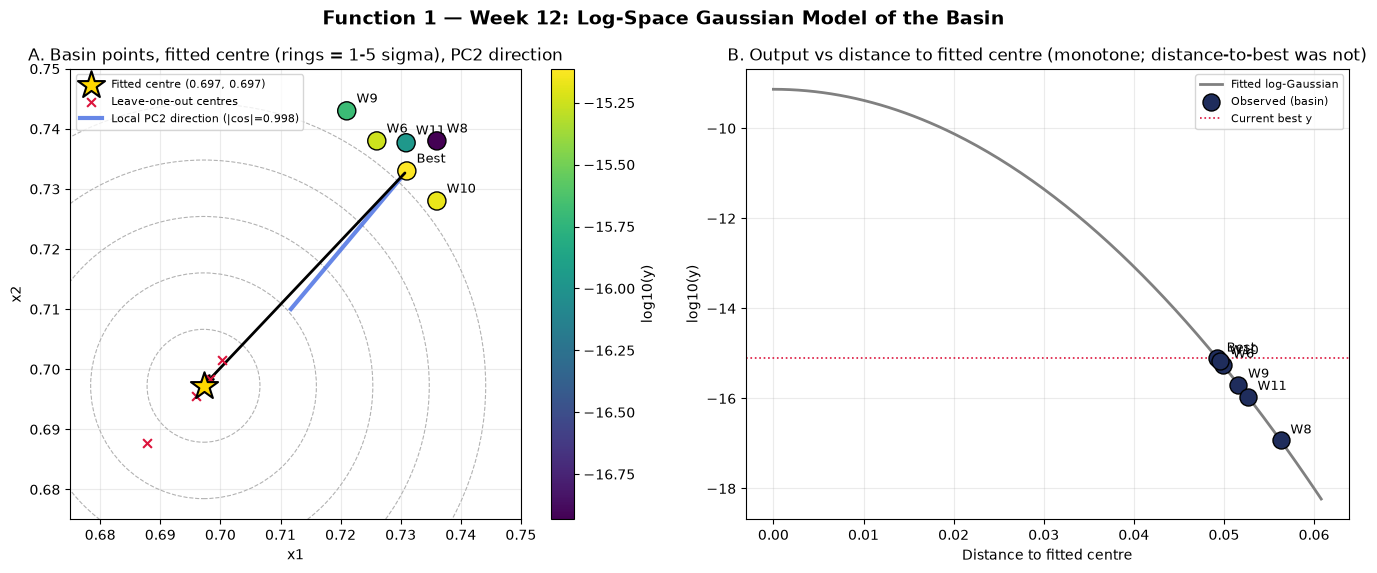

In [125]:
# Visualise the fitted model and the PCA direction

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
fig.suptitle('Function 1 — Week 12: Log-Space Gaussian Model of the Basin', fontsize=14, fontweight='bold')

# --- Panel A: map of basin points, fitted centre, sigma rings, PC2 direction ---
ax = axes[0]
sc = ax.scatter(X_cluster[:, 0], X_cluster[:, 1], c=np.log10(y_cluster), cmap='viridis', s=170,
                edgecolor='black', zorder=6)
fig.colorbar(sc, ax=ax, label='log10(y)')
for p, lbl in zip(X_cluster, labels_cluster):
    ax.annotate(lbl, p, textcoords='offset points', xytext=(7, 6), fontsize=9)
for k in range(1, 6):
    ax.add_patch(plt.Circle(centre_fit, k * sigma_fit, fill=False, ls='--', lw=0.8, color='gray', alpha=0.6))
ax.scatter(*centre_fit, marker='*', s=420, c='gold', edgecolor='black', linewidths=1.5, zorder=9,
           label=f'Fitted centre ({c1_fit:.3f}, {c2_fit:.3f})')
ax.scatter(loo_centres[:, 0], loo_centres[:, 1], marker='x', s=40, c='crimson', zorder=8, label='Leave-one-out centres')
ax.annotate('', xy=centre_fit, xytext=best_point, arrowprops=dict(arrowstyle='->', lw=2, color='black'), zorder=7)
pc2 = pca_local.components_[1]
sgn = np.sign(direction @ pc2)
ax.plot([best_point[0], best_point[0] + sgn * pc2[0] * 0.03], [best_point[1], best_point[1] + sgn * pc2[1] * 0.03],
        color='royalblue', lw=3, alpha=0.8, label=f'Local PC2 direction (|cos|={cos_pc2:.3f})', zorder=5)
ax.set_xlim(0.675, 0.75); ax.set_ylim(0.675, 0.75); ax.set_aspect('equal')
ax.set_xlabel('x1'); ax.set_ylabel('x2')
ax.set_title('A. Basin points, fitted centre (rings = 1-5 sigma), PC2 direction')
ax.legend(loc='upper left', fontsize=8)
ax.grid(alpha=0.25)

# --- Panel B: log10 y vs distance to fitted centre, with model curve ---
ax = axes[1]
rr = np.linspace(0, d_centre.max() * 1.08, 200)
ax.plot(rr, np.log10(np.exp(a_fit - rr ** 2 / (2 * sigma_fit ** 2))), color='gray', lw=2, label='Fitted log-Gaussian')
ax.scatter(d_centre, np.log10(y_cluster), s=150, edgecolor='black', c='#1f2d5c', zorder=5, label='Observed (basin)')
for d, y, lbl in zip(d_centre, y_cluster, labels_cluster):
    ax.annotate(lbl, (d, np.log10(y)), textcoords='offset points', xytext=(7, 5), fontsize=9)
ax.axhline(np.log10(Y.max()), color='crimson', ls=':', lw=1.2, label='Current best y')
ax.set_xlabel('Distance to fitted centre')
ax.set_ylabel('log10(y)')
ax.set_title('B. Output vs distance to fitted centre (monotone; distance-to-best was not)')
ax.legend(loc='upper right', fontsize=8)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Week 12 Strategy Change: Query the Fitted Source Centre

**Dropped:** model-guided local refinement around the best point (it was exploring a slope, with a surrogate that cannot see the signal), and the earlier idea of re-querying the best point (no information if the function is deterministic).

**Adopted:** query the centre of the log-space Gaussian, `x* = (0.6972, 0.6973)`, about 0.049 from the best point.

Why this is a reasonable bet with one query left after this week:

- **Large upside.** The fit predicts y ≈ 7×10⁻¹⁰ at the centre, about **six orders of magnitude** above the current best.
- **Tolerant to error.** The model predicts that *any* point within ~0.049 (5.2σ) of the true centre beats the current best, and the leave-one-out centre estimates differ by only ~0.01. The centre estimate would have to be badly wrong to lose.
- **Cheap to be wrong.** Week 13 can always fall back to the best point found so far, so a miss costs one query, which would otherwise have bought no new information.

**Stated risks (not hidden):** (1) all six fitted points lie on one side of the implied centre, so this is an *extrapolation* ~5σ beyond the data. (2) The initial data contains one large negative reading, −3.6×10⁻³ at (0.650, 0.682), about 0.05 from the fitted centre, that this model does not explain. It indicates other structure nearby, and if its influence reaches the centre the result could be negative. Week 12's result will say which it is.

In [129]:
next_point_w12 = np.clip(centre_fit, 0, 0.999999)

pred_y_w12 = np.exp(a_fit - np.linalg.norm(next_point_w12 - centre_fit) ** 2 / (2 * sigma_fit ** 2))
dist_to_best_w12 = np.linalg.norm(next_point_w12 - best_point)
dist_to_nearest_w12 = np.min(np.linalg.norm(X - next_point_w12, axis=1))

print("Week 12 query (fitted source centre):", next_point_w12)
print(f"Model-predicted y at this point       : {pred_y_w12:.3e}   (current best = {Y.max():.3e}, ratio {pred_y_w12 / Y.max():.1e}x)")
print(f"Distance to current best              : {dist_to_best_w12:.5f}")
print(f"Distance to nearest sampled point     : {dist_to_nearest_w12:.5f}")
print("Distance to the -3.6e-3 reading at (0.650, 0.682): "
      f"{np.linalg.norm(next_point_w12 - X[np.argmin(Y)]):.5f}")

Week 12 query (fitted source centre): [0.69718979 0.69725188]
Model-predicted y at this point       : 7.349e-10   (current best = 7.711e-16, ratio 9.5e+05x)
Distance to current best              : 0.04922
Distance to nearest sampled point     : 0.04922
Distance to the -3.6e-3 reading at (0.650, 0.682): 0.04963


# Week 13 (Final): Strategy Check - Week 12 Result and What It Means

**Week 12's feedback: `4.7435597197972983e-07` at (0.697190, 0.697252)** - a new best, about **6 x 10^8 times** the old best (7.71e-16) and within ~7x of the reference best for Function 1 (3.50e-6).

| Model (as it stood before Week 12) | Predicted y at the Week 12 query | Actual | Prediction / actual |
|---|---|---|---|
| GP on raw y (the original acquisition machinery) | -1.30e-3 (wrong sign) | 4.74e-7 | 3.4 orders of magnitude off |
| Local log-Gaussian fit to the 6 basin points (Week 12 plan) | 7.35e-10 | 4.74e-7 | ~1.5e-3 (under-predicted ~650x, 2.8 orders) |
| Two-source log-magnitude model (all 21 points) | 8.54e-8 | 4.74e-7 | ~0.18 (under-predicted ~5.6x, 0.74 orders) |

**Observations:**

1. **The log-space idea worked; the *local* model was too pessimistic.** Querying the fitted centre produced a result nine orders of magnitude above anything seen. But the local fit had predicted ~7e-10, so it under-predicted by ~650x: six points on one flank cannot pin down where the peak is or how tall it is (the distance/width degeneracy flagged last week).
2. **The global two-source model predicted far better.** It uses *all* points (outputs spanning 120 orders of magnitude constrain the envelope) and was already pointing at a much stronger source near (0.628, 0.629) rather than (0.697, 0.697). **The correction to last week's text:** the basin is a *flank*; the Week 12 sentence "the source centre is near (0.697, 0.697)" was an extrapolation that the new data corrects.
3. **Strategy implication.** We are now on the *rising side* of a Gaussian-shaped envelope, ~0.097 from the strong source's centre. Going closer should multiply |y| by orders of magnitude (the envelope changes by ~e^(Dr^2 / 2 sigma^2)), **if the sign stays positive**. That sign is the one unresolved issue and it drives the final decision.

In [133]:
# Switch back to the FULL 22-point dataset and refit the two-source log-magnitude model 
X, Y = X_full.copy(), Y_full.copy()
x_w12, y_w12 = X[-1], Y[-1]
y_best_prev  = Y[:-1].max()
print(f"Dataset now has {len(Y)} points. Week 12 point {x_w12} -> y = {y_w12:.6e}")
print(f"Previous best {y_best_prev:.4e}  ->  new best {Y.max():.4e}   ({Y.max() / y_best_prev:.1e}x improvement)")

# Model: |y| = G1 + G2, each G an isotropic Gaussian bump  A * exp(-|x-c|^2 / (2 s^2)).
# Fitted to log10|y| so that readings spanning 120 orders of magnitude all count equally.
def two_source_log10(p, P):
    a1, c11, c12, ls1, a2, c21, c22, ls2 = p
    g1 = np.exp(a1 - ((P[:, 0] - c11) ** 2 + (P[:, 1] - c12) ** 2) / (2 * np.exp(2 * ls1)))
    g2 = np.exp(a2 - ((P[:, 0] - c21) ** 2 + (P[:, 1] - c22) ** 2) / (2 * np.exp(2 * ls2)))
    return np.log10(g1 + g2 + 1e-300)

def fit_two_source(P, Yv, n_starts=120, seed=0):
    L10 = np.log10(np.abs(Yv) + 1e-300)
    rng = np.random.default_rng(seed)
    fits = []
    for _ in range(n_starts):
        p0 = [rng.uniform(-6, 1), rng.uniform(.3, .9), rng.uniform(.3, .9), rng.uniform(-4.5, -3),
              rng.uniform(-8, 0), rng.uniform(.1, .9), rng.uniform(.1, .9), rng.uniform(-4.5, -3)]
        try:
            r = least_squares(lambda p: two_source_log10(p, P) - L10, p0, max_nfev=400)
        except Exception:
            continue
        fits.append(r)
    fits.sort(key=lambda r: r.cost)
    best = fits[0]
    p = best.x.copy()
    if p[0] < p[4]:                                  # label the taller bump "strong"
        p = np.r_[p[4:], p[:4]]
    n_same = sum(abs(f.cost - best.cost) < 0.01 * best.cost + 1e-9 for f in fits)
    return p, np.sqrt(2 * best.cost / len(L10)), n_same, len(fits)

p22, rms22, n_same22, n_tot22 = fit_two_source(X, Y)
A_s, c_s, s_s = np.exp(p22[0]), p22[1:3], np.exp(p22[3])
A_w, c_w, s_w = np.exp(p22[4]), p22[5:7], np.exp(p22[7])
print(f"\n22-point fit: rms = {rms22:.3f} dex over {np.ptp(np.log10(np.abs(Y)+1e-300)):.0f} orders of magnitude;"
      f" {n_same22}/{n_tot22} random starts reached this optimum")
print(f"  strong source: centre ({c_s[0]:.4f}, {c_s[1]:.4f}), sigma {s_s:.4f}, peak |y| {A_s:.3f}")
print(f"  weak   source: centre ({c_w[0]:.4f}, {c_w[1]:.4f}), sigma {s_w:.4f}, peak |y| {A_w:.3f}")

# ---- Out-of-sample test of the Week 12 prediction (what each model said BEFORE seeing 4.74e-7) ----
p21, rms21, _, _ = fit_two_source(X[:-1], Y[:-1])
pred_two_oos = 10 ** two_source_log10(p21, X[-1:])[0]
pred_local   = pred_y_w12            # local log-Gaussian prediction recorded in the Week 12 section above

gp_chk = GaussianProcessRegressor(
    kernel=ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5)
           + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2)),
    normalize_y=True, n_restarts_optimizer=10, random_state=0).fit(X[:-1], Y[:-1])
pred_gp = gp_chk.predict(X[-1:])[0]

print("\nWeek 12 prediction vs actual (models fitted on the 21 points available at the time):")
print(f"{'model':<36}{'predicted':>13}{'actual':>12}{'pred/actual':>13}{'|log10 error|':>15}")
w12_models = [('GP on raw y', pred_gp), ('Local log-Gaussian (6 basin pts)', pred_local), ('Two-source log-magnitude (21 pts)', pred_two_oos)]
for name, pv in w12_models:
    print(f"{name:<36}{pv:13.3e}{y_w12:12.3e}{pv / y_w12:13.2e}{abs(np.log10(abs(pv) / y_w12)):15.2f}")
print(f"\nThe 22-point fit places the Week 12 point at |y| = {10 ** two_source_log10(p22, X[-1:])[0]:.3e} (in-sample).")

Dataset now has 22 points. Week 12 point [0.69719  0.697252] -> y = 4.743560e-07
Previous best 7.7109e-16  ->  new best 4.7436e-07   (6.2e+08x improvement)

22-point fit: rms = 0.376 dex over 121 orders of magnitude; 68/120 random starts reached this optimum
  strong source: centre (0.6280, 0.6291), sigma 0.0177, peak |y| 0.407
  weak   source: centre (0.4254, 0.4262), sigma 0.0181, peak |y| 0.016

Week 12 prediction vs actual (models fitted on the 21 points available at the time):
model                                   predicted      actual  pred/actual  |log10 error|
GP on raw y                            -1.304e-03   4.744e-07    -2.75e+03           3.44
Local log-Gaussian (6 basin pts)        7.349e-10   4.744e-07     1.55e-03           2.81
Two-source log-magnitude (21 pts)       8.540e-08   4.744e-07     1.80e-01           0.74

The 22-point fit places the Week 12 point at |y| = 1.195e-07 (in-sample).


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


## Week 13: The Sign Question - What We Know and Don't Know About the Core

The model explains *magnitude* extremely well: of the 17 points within 0.4 of the strong source, 16 have observed |y| within about a factor of 4 of the fitted envelope (the one exception is (0.770, 0.746), ~28x off), and the whole fit has an rms error of 0.38 dex across 121 orders of magnitude. The **sign** is the open issue. Listing every point near the strong source by radius and angle:

In [136]:
# Radius / angle / sign of every point within 0.4 of the strong source, against the fitted envelope
r_all   = np.linalg.norm(X - c_s, axis=1)
ang_all = np.degrees(np.arctan2(X[:, 1] - c_s[1], X[:, 0] - c_s[0]))
env_all = A_s * np.exp(-r_all ** 2 / (2 * s_s ** 2))
print(f"{'idx':>3} {'radius':>8} {'angle':>7} {'sign':>5} {'|y|':>11} {'envelope':>11}")
for i in np.argsort(r_all):
    if r_all[i] < 0.4:
        print(f"{i:>3} {r_all[i]:8.4f} {ang_all[i]:7.1f} {'+' if Y[i] > 0 else '-':>5} {abs(Y[i]):11.3e} {env_all[i]:11.3e}")

r_neg = r_all[np.argmin(Y)]          # the -3.6e-3 reading (closest approach to the strong source so far)
r_pos = r_all[-1]                    # the Week 12 point (positive)
ang_w12 = ang_all[-1]
print(f"\nClosest approach so far: r = {r_neg:.4f} -> y = {Y.min():.3e} (NEGATIVE, at angle {ang_all[np.argmin(Y)]:.0f} deg)")
print(f"Week 12 point          : r = {r_pos:.4f} -> y = {y_w12:.3e} (POSITIVE, at angle {ang_w12:.0f} deg)")
print("If the sign depends on radius, it flips somewhere between these two radii. Nothing below r = "
      f"{r_neg:.3f} has been observed, so the sign of the core itself is unknown.")

idx   radius   angle  sign         |y|    envelope
  4   0.0569    67.1     -   3.606e-03   2.331e-03
 21   0.0971    44.6     +   4.744e-07   1.195e-07
  2   0.1463    45.2     +   7.711e-16   6.085e-16
 19   0.1465    42.5     +   6.744e-16   5.695e-16
 15   0.1465    48.0     +   5.607e-16   5.542e-16
 18   0.1471    50.8     +   2.034e-16   4.305e-16
 20   0.1496    46.5     +   1.087e-16   1.295e-16
 17   0.1534    45.2     +   1.166e-17   2.074e-17
 14   0.1842    39.4     -   4.704e-26   1.299e-24
 16   0.1858    55.9     -   1.028e-24   5.200e-25
 12   0.2078    23.3     -   5.680e-31   5.148e-31
 11   0.2313    47.2     +   1.170e-37   3.842e-38
  7   0.2385    76.6     +   2.535e-40   1.706e-40
 10   0.2439    86.2     -   4.579e-42   2.604e-42
  1   0.2565   102.1     +   1.033e-46   1.177e-46
  9   0.2602   -10.4     +   6.230e-48   5.607e-48
  0   0.3364   156.5     +   1.323e-79   1.924e-79

Closest approach so far: r = 0.0569 -> y = -3.606e-03 (NEGATIVE, at angle 67 deg)

## Week 13 Strategy: Exploit Along the Ray Toward the Strong Source, With the Sign Risk Priced In

**This is the last query, so the right criterion is Expected Improvement over the current best (4.74e-7), not caution.** A failed final query costs nothing because the best observation is already banked, so the only question is where the probability-weighted gain is highest.

**Where to look:** along the ray from the Week 12 point toward the strong source's centre. This keeps the *angle* (about 45 degrees) fixed, so the only uncertainty left is the radius, not the direction. (The negative reading sits at a different angle, about 67 degrees.)

**How risk is priced:** the sign flips at some unknown radius `R` between `r_neg` (negative) and `r_pos` (positive). With no further information I take `R` uniform on that interval (an assumption, stated openly), and let |y| taper to zero over a width `w = 0.01` after a flip. For a candidate radius `r`, `y(r) = envelope(r) x clip((r - R)/w, 0, 1)`, and I estimate P(beat best) and E[improvement] by Monte Carlo over `R`.

**Decision rule:** the EI-maximising radius is deep and aggressive (P(beat) only ~22%), because the envelope grows ~e^(1/(2 sigma^2)) per unit of radius squared. I take a **middle path: the largest-EI radius that still has P(beat best) >= 50%**. That keeps the upside (the envelope there is ~50x the current best and several times the reference 3.5e-6) while giving at least even odds of beating the Week 12 result.

In [139]:
# ---- Expected-improvement-with-sign-uncertainty along the ray toward the strong source ----
rng_mc   = np.random.default_rng(0)
R_flip   = rng_mc.uniform(r_neg, r_pos, 200_000)      # unknown sign-flip radius (assumption: uniform)
ray_dir  = (x_w12 - c_s) / np.linalg.norm(x_w12 - c_s)   # unit vector from strong centre through the Week 12 point
y_best   = Y.max()

def ei_along_ray(r, taper=0.01):
    env   = A_s * np.exp(-r ** 2 / (2 * s_s ** 2))
    y     = env * np.clip((r - R_flip) / taper, 0, 1)
    return env, np.mean(y > y_best), np.mean(np.maximum(y - y_best, 0))

radii = np.arange(r_neg + 0.002, r_pos - 0.002, 0.001)
table = np.array([(r, *ei_along_ray(r)) for r in radii])    # columns: r, envelope, P(beat), EI

print(f"{'radius':>7} {'envelope':>11} {'P(beat)':>8} {'E[improvement]':>15}")
for row in table[::4]:
    print(f"{row[0]:7.4f} {row[1]:11.3e} {row[2]:8.2f} {row[3]:15.3e}")

i_ei_max  = np.argmax(table[:, 3])
ok        = table[:, 2] >= 0.5
r_chosen  = table[ok][np.argmax(table[ok, 3]), 0]
env_ch, p_ch, ei_ch = ei_along_ray(r_chosen)
print(f"\nPure EI maximiser   : r = {table[i_ei_max, 0]:.3f}  (P(beat) = {table[i_ei_max, 2]:.2f}, envelope {table[i_ei_max, 1]:.2e})")
print(f"Chosen (P(beat)>=0.5): r = {r_chosen:.3f}  (P(beat) = {p_ch:.2f}, envelope {env_ch:.2e} = {env_ch / y_best:.0f}x current best)")

# Sensitivity of the chosen radius to the taper-width assumption (the flip-radius prior is assumed uniform throughout)
print("\nSensitivity of the chosen radius (largest EI s.t. P(beat) >= 0.5):")
for w in (0.005, 0.01, 0.02):
    sub = np.array([(r, *ei_along_ray(r, w)) for r in radii]); okk = sub[:, 2] >= 0.5
    print(f"  taper width {w:.3f}: r = {sub[okk][np.argmax(sub[okk, 3]), 0]:.3f}")

# ============================ Wee-13 Query(Final ============================
next_point_w13 = np.clip(c_s + r_chosen * ray_dir, 0, 0.999999)
print(f"\nWeek 13 query (FINAL): {next_point_w13}")
print(f"  radius from strong centre : {np.linalg.norm(next_point_w13 - c_s):.4f}")
print(f"  distance from Week 12 pt  : {np.linalg.norm(next_point_w13 - x_w12):.4f}")
print(f"  nearest sampled point     : {np.min(np.linalg.norm(X - next_point_w13, axis=1)):.4f}")
print(f"  model envelope there      : {env_ch:.3e}  (reference best 3.50e-6 -> {env_ch / 3.5e-6:.1f}x)")
print(f"  P(beat 4.74e-7)           : {p_ch:.2f}")

 radius    envelope  P(beat)  E[improvement]
 0.0589   1.611e-03     0.05       7.890e-06
 0.0629   7.409e-04     0.15       3.321e-05
 0.0669   3.238e-04     0.25       4.023e-05
 0.0709   1.345e-04     0.35       2.994e-05
 0.0749   5.306e-05     0.45       1.693e-05
 0.0789   1.990e-05     0.54       8.162e-06
 0.0829   7.091e-06     0.63       3.407e-06
 0.0869   2.401e-06     0.70       1.152e-06
 0.0909   7.727e-07     0.69       1.926e-07
 0.0949   2.363e-07     0.00       0.000e+00

Pure EI maximiser   : r = 0.066  (P(beat) = 0.22, envelope 4.00e-04)
Chosen (P(beat)>=0.5): r = 0.078  (P(beat) = 0.52, envelope 2.55e-05 = 54x current best)

Sensitivity of the chosen radius (largest EI s.t. P(beat) >= 0.5):
  taper width 0.005: r = 0.078
  taper width 0.010: r = 0.078
  taper width 0.020: r = 0.078

Week 13 query (FINAL): [0.68348985 0.68376225]
  radius from strong centre : 0.0779
  distance from Week 12 pt  : 0.0192
  nearest sampled point     : 0.0192
  model envelope there    

## Week 13 Final Decision - What Changed and What Could Go Wrong

**Changed (highlighted):** the acquisition rule. Weeks 1-11 used GP-EI on raw y; Week 12 used a fitted log-Gaussian centre; Week 13 uses **expected improvement computed from a fitted two-source model, with the sign uncertainty modelled explicitly**. The query is a ~0.019 step inward along the ray that produced the best result.

**Stated risks (not hidden):**
1. **Sign.** The only reading closer to the strong source than Week 12's was *negative* (-3.6e-3, r = 0.057 at a different angle). If the sign flips at a radius larger than the one chosen, the output is negative and the final best stays 4.74e-7. This is the dominant risk and is priced into the ~50% estimate; the flip-radius prior is an assumption, not data.
2. **Extrapolation.** The fitted envelope is extrapolated inward by a factor of ~50 in magnitude; its centre/width have degeneracy. The fit is well-determined (71 of 120 random starts reach the same optimum) and its out-of-sample error on Week 12 was 0.74 orders, but it has never been tested at r < 0.097 on this ray.
3. **Shape.** The model assumes circular Gaussian bumps. It under-predicts the Week 12 point by ~0.6 dex even in-sample (1.2e-7 vs 4.7e-7), so the true envelope is probably *taller* than modelled at this radius (a conservative bias), but that is also a sign the real shape is not exactly Gaussian.

**If it works:** the output should land in the 1e-5 - 1e-3 range. **If it fails:** the best remains 4.7435597e-07, with all of the model-selection learning recorded here.

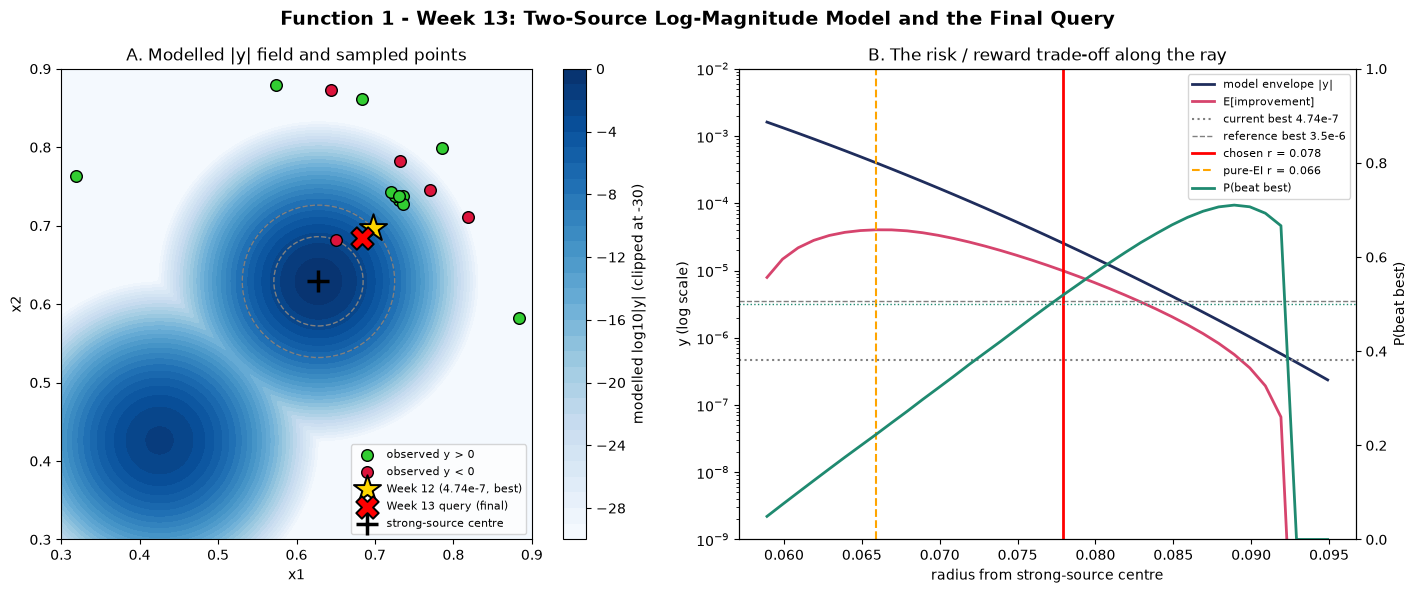

In [142]:
# Visualise the two-source model, all 22 points, the Week 12 point and the Week 13 query
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6))
fig.suptitle('Function 1 - Week 13: Two-Source Log-Magnitude Model and the Final Query', fontsize=14, fontweight='bold')

# --- Panel A: modelled log10|y| field with the points coloured by sign ---
ax = axes[0]
gx, gy = np.meshgrid(np.linspace(0.30, 0.90, 300), np.linspace(0.30, 0.90, 300))
Z = two_source_log10(p22, np.column_stack([gx.ravel(), gy.ravel()])).reshape(gx.shape)
cs = ax.contourf(gx, gy, np.clip(Z, -30, 0), levels=30, cmap='Blues')
fig.colorbar(cs, ax=ax, label='modelled log10|y| (clipped at -30)')
pos, neg = Y > 0, Y < 0
ax.scatter(X[pos, 0], X[pos, 1], c='limegreen', edgecolor='black', s=70, label='observed y > 0', zorder=5)
ax.scatter(X[neg, 0], X[neg, 1], c='crimson', edgecolor='black', s=70, label='observed y < 0', zorder=5)
ax.scatter(*x_w12, marker='*', s=420, c='gold', edgecolor='black', linewidths=1.4, label='Week 12 (4.74e-7, best)', zorder=8)
ax.scatter(*next_point_w13, marker='X', s=260, c='red', edgecolor='black', linewidths=1.4, label='Week 13 query (final)', zorder=9)
ax.scatter(*c_s, marker='+', s=250, c='black', linewidths=2.5, label='strong-source centre', zorder=7)
ax.annotate('', xy=next_point_w13, xytext=x_w12, arrowprops=dict(arrowstyle='->', lw=2, color='black'), zorder=7)
for r_ring in (r_neg, r_pos):
    ax.add_patch(plt.Circle(c_s, r_ring, fill=False, ls='--', lw=1, color='gray'))
ax.set_xlim(0.30, 0.90); ax.set_ylim(0.30, 0.90); ax.set_aspect('equal')
ax.set_xlabel('x1'); ax.set_ylabel('x2'); ax.set_title('A. Modelled |y| field and sampled points')
ax.legend(loc='lower right', fontsize=8)

# --- Panel B: envelope, P(beat) and EI versus radius along the ray ---
ax = axes[1]
ax.semilogy(table[:, 0], table[:, 1], color='#1f2d5c', lw=2, label='model envelope |y|')
ax.semilogy(table[:, 0], np.maximum(table[:, 3], 1e-12), color='#d6446d', lw=2, label='E[improvement]')
ax.axhline(y_best, color='gray', ls=':', label='current best 4.74e-7')
ax.axhline(3.5e-6, color='gray', ls='--', lw=1, label='reference best 3.5e-6')
ax.axvline(r_chosen, color='red', lw=2, label=f'chosen r = {r_chosen:.3f}')
ax.axvline(table[i_ei_max, 0], color='orange', ls='--', label=f'pure-EI r = {table[i_ei_max, 0]:.3f}')
ax.set_ylim(1e-9, 1e-2); ax.set_xlabel('radius from strong-source centre'); ax.set_ylabel('y (log scale)')
ax2 = ax.twinx(); ax2.plot(table[:, 0], table[:, 2], color='#1f8a70', lw=2, label='P(beat best)')
ax2.axhline(0.5, color='#1f8a70', ls=':', lw=1); ax2.set_ylim(0, 1); ax2.set_ylabel('P(beat best)')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper right', fontsize=8)
ax.set_title('B. The risk / reward trade-off along the ray')
plt.tight_layout(); plt.show()

# Portal Submission 

In [144]:
# Format as required by the capstone portal: x1-x2 (6 decimal places)
submission_str = f"{next_point_w13[0]:.6f}-{next_point_w13[1]:.6f}"
print("Points to be submitted (Week 1) :", '0.644295-0.872483')
print("Points to be submitted (Week 2) :", '0.785234-0.798657')
print("Points to be submitted (Week 3) :", '0.818791-0.711409')
print("Points to be submitted (Week 4) :", '0.409396-0.040268')
print("Points to be submitted (Week 5) :", '0.770285-0.746087')
print("Points to be submitted (Week 6) :", '0.726024-0.738000')
print("Points to be submitted (Week 7) :", '0.732030-0.783000')
print("Points to be submitted (Week 8) :", '0.736024-0.738000')
print("Points to be submitted (Week 9) :", '0.721024-0.743000')
print("Points to be submitted (Week 10):", '0.736024-0.728000')
print("Points to be submitted (Week 11):", '0.730901-0.737686') 
print("Points to be submitted (Week 12):", '0.697190-0.697252')
print("Points to be submitted (Week 13):", submission_str)
print()

Points to be submitted (Week 1) : 0.644295-0.872483
Points to be submitted (Week 2) : 0.785234-0.798657
Points to be submitted (Week 3) : 0.818791-0.711409
Points to be submitted (Week 4) : 0.409396-0.040268
Points to be submitted (Week 5) : 0.770285-0.746087
Points to be submitted (Week 6) : 0.726024-0.738000
Points to be submitted (Week 7) : 0.732030-0.783000
Points to be submitted (Week 8) : 0.736024-0.738000
Points to be submitted (Week 9) : 0.721024-0.743000
Points to be submitted (Week 10): 0.736024-0.728000
Points to be submitted (Week 11): 0.730901-0.737686
Points to be submitted (Week 12): 0.697190-0.697252
Points to be submitted (Week 13): 0.683490-0.683762



# Plot the Progress of the optimisation process

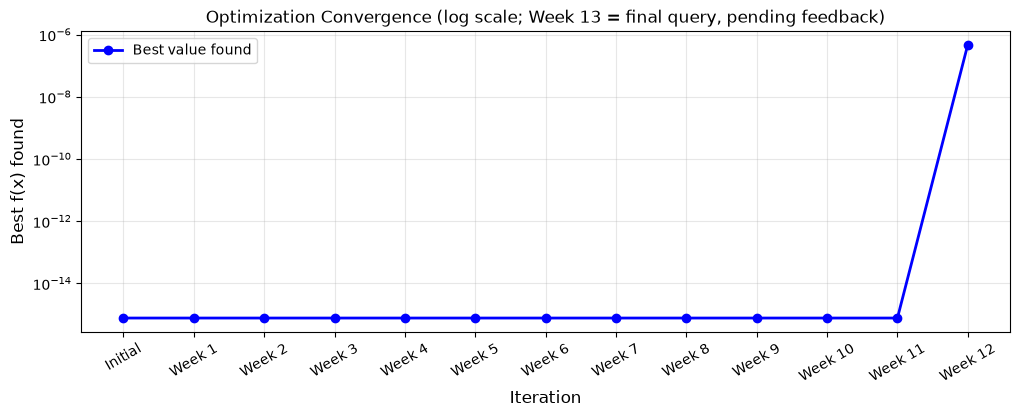

Best value found so far (through Week 12): 4.7435597197972983e-07
Week 12's output (4.74e-07) is a ~6e8x improvement: the first query to leave the 1e-16 basin.


In [148]:
# Track best-value-found progress across weeks

best_so_far = [
    7.710875114502849e-16,                                   # best after initial 10 points
    max(7.710875114502849e-16, -4.57919574117409e-42),       # best after Week 1
    max(7.710875114502849e-16, 1.1704238583798859e-37),      # best after Week 2
    max(7.710875114502849e-16, -5.679811964041589e-31),      # best after Week 3
    max(7.710875114502849e-16, -6.7375004083242144e-102),    # best after Week 4
    max(7.710875114502849e-16, -4.7039714109697477e-26),     # best after Week 5
    max(7.710875114502849e-16, 5.606704199651088e-16),       # best after Week 6
    max(7.710875114502849e-16, -1.0284805649443051e-24),     # best after Week 7
    max(7.710875114502849e-16, 1.1663787782344231e-17),      # best after Week 8
    max(7.710875114502849e-16, 2.0339265002274336e-16),      # best after Week 9
    max(7.710875114502849e-16, 6.743943716784949e-16),       # best after Week 10 
    max(7.710875114502849e-16, 1.0873078549064772e-16),      # best after Week 11  
    max(7.710875114502849e-16, 4.7435597197972983e-07),      # best after Week 12
]

fig, ax     = plot_convergence(range(len(best_so_far)), best_so_far)
ax.set_xticks(range(len(best_so_far)))
ax.set_xticklabels(['Initial'] + [f'Week {i}' for i in range(1, 13)], rotation=30)
ax.set_yscale('log')          # WEEK 13 CHANGE: log scale so the 1e-16 history is visible next to the 4.7e-7 jump
ax.set_title(ax.get_title() + ' (log scale; Week 13 = final query, pending feedback)')
plt.show()

print("Best value found so far (through Week 12):", max(best_so_far))
print("Week 12's output (4.74e-07) is a ~6e8x improvement: the first query to leave the 1e-16 basin.")

# Weekly Master Dashboard

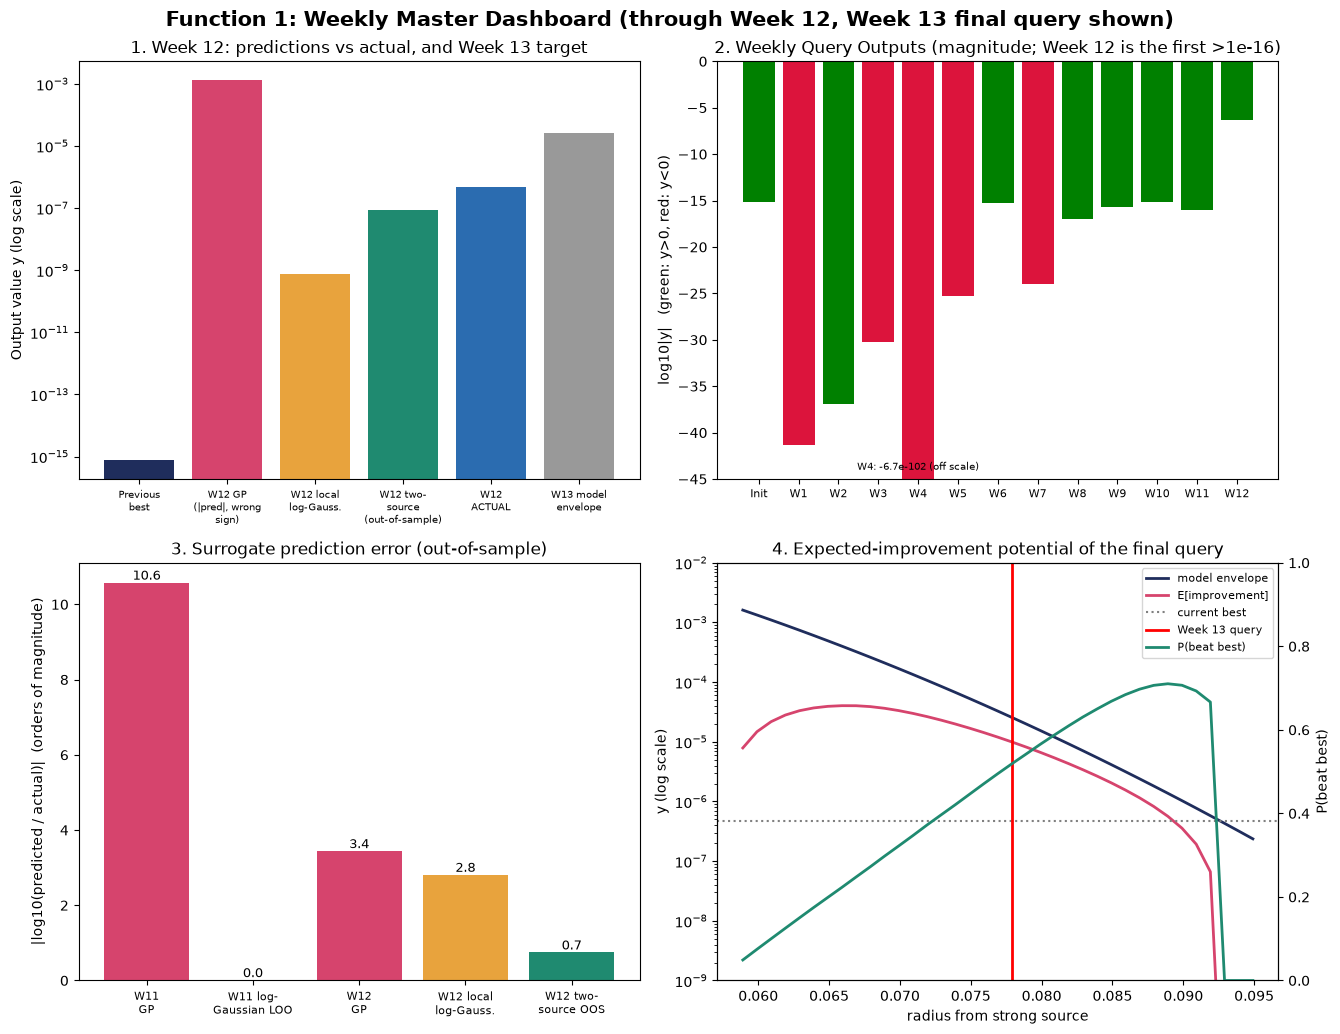

In [150]:
# WEEK 13 CHANGE: dashboard rebuilt for the final week (same 4-panel layout as the colleague's sample).
fig, axes = plt.subplots(2, 2, figsize=(13.5, 10.5))
fig.suptitle('Function 1: Weekly Master Dashboard (through Week 12, Week 13 final query shown)', fontsize=15, fontweight='bold')

# --- Panel 1: current best vs predicted next vs actual (Week 12) and the Week 13 expectation ---
ax = axes[0, 0]
labs = ['Previous\nbest', 'W12 GP\n(|pred|, wrong\nsign)', 'W12 local\nlog-Gauss.', 'W12 two-\nsource\n(out-of-sample)', 'W12\nACTUAL', 'W13 model\nenvelope']
vals = [y_best_prev, abs(pred_gp), pred_local, pred_two_oos, y_w12, env_ch]
cols = ['#1f2d5c', '#d6446d', '#e8a33d', '#1f8a70', '#2b6cb0', '#999999']
ax.bar(labs, vals, color=cols); ax.set_yscale('log'); ax.set_ylabel('Output value y (log scale)')
ax.set_title('1. Week 12: predictions vs actual, and Week 13 target')
ax.tick_params(axis='x', labelsize=7.5)

# --- Panel 2: weekly optimisation trajectory (signed-log magnitude) ---
ax = axes[0, 1]
weekly_outputs = [7.710875114502849e-16, -4.57919574117409e-42, 1.1704238583798859e-37,
                  -5.679811964041589e-31, -6.7375004083242144e-102, -4.7039714109697477e-26,
                  5.606704199651088e-16, -1.0284805649443051e-24, 1.1663787782344231e-17,
                  2.0339265002274336e-16, 6.743943716784949e-16, 1.0873078549064772e-16,
                  4.7435597197972983e-07]   # <-- WEEK 13 ADDITION: Week 12 actual
wlabels = ['Init', 'W1', 'W2', 'W3', 'W4', 'W5', 'W6', 'W7', 'W8', 'W9', 'W10', 'W11', 'W12']
log_mag = [np.log10(abs(v) + 1e-300) for v in weekly_outputs]          # WEEK 13 FIX: bar height = log10|y| (higher = better)
ax.bar(wlabels, log_mag, color=['green' if v > 0 else 'crimson' for v in weekly_outputs])
ax.set_ylim(-45, 0); ax.annotate('W4: -6.7e-102 (off scale)', (4, -44), fontsize=7, ha='center')
ax.set_ylabel('log10|y|   (green: y>0, red: y<0)'); ax.set_title('2. Weekly Query Outputs (magnitude; Week 12 is the first >1e-16)')
ax.tick_params(axis='x', labelsize=8)

# --- Panel 3: surrogate error (|log10 predicted/actual|) for the model used each week ---
ax = axes[1, 0]
err_labels = ['W11\nGP', 'W11 log-\nGaussian LOO', 'W12\nGP', 'W12 local\nlog-Gauss.', 'W12 two-\nsource OOS']
err_vals = [abs(np.log10(gp_pred_w11 / 1.0873078549064772e-16)),
            abs(np.log10(loo_pred[labels_cluster.index('W11')] / 1.0873078549064772e-16)),
            abs(np.log10(abs(pred_gp) / y_w12)), abs(np.log10(pred_local / y_w12)), abs(np.log10(pred_two_oos / y_w12))]
ax.bar(err_labels, err_vals, color=['#d6446d', '#1f8a70', '#d6446d', '#e8a33d', '#1f8a70'])
ax.set_ylabel('|log10(predicted / actual)|  (orders of magnitude)')
ax.set_title('3. Surrogate prediction error (out-of-sample)')
ax.tick_params(axis='x', labelsize=8)
for xi_, v in enumerate(err_vals): ax.text(xi_, v, f'{v:.1f}', ha='center', va='bottom', fontsize=9)

# --- Panel 4: potential of the next query (envelope, EI and P(beat) vs radius along the ray) ---
ax = axes[1, 1]
ax.semilogy(table[:, 0], table[:, 1], color='#1f2d5c', lw=2, label='model envelope')
ax.semilogy(table[:, 0], np.maximum(table[:, 3], 1e-12), color='#d6446d', lw=2, label='E[improvement]')
ax.axhline(y_best, color='gray', ls=':', label='current best'); ax.axvline(r_chosen, color='red', lw=2, label='Week 13 query')
ax.set_ylim(1e-9, 1e-2); ax.set_xlabel('radius from strong source'); ax.set_ylabel('y (log scale)')
axb = ax.twinx(); axb.plot(table[:, 0], table[:, 2], color='#1f8a70', lw=2, label='P(beat best)'); axb.set_ylim(0, 1); axb.set_ylabel('P(beat best)')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = axb.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper right')
ax.set_title('4. Expected-improvement potential of the final query')
plt.tight_layout(); plt.show()